# <center> Модель прогнозирования стоимости жилья для агенства недвижимости

## <center> 1. Постановка задачи

Задача — разработать модель, которая позволила бы агентству недвижимости обойти конкурентов по скорости и качеству совершения сделок.

**Необходимо:**
1. Провести разведывательный анализ и очистку исходных данных.
2. Выделить наиболее значимые факторы, влияющие на стоимость недвижимости.
3. Построить модель для прогнозирования стоимости недвижимости.
4. Разработать небольшой веб-сервис, на вход которому поступают данные о некоторой выставленной на продажу недвижимости, а сервис прогнозирует его стоимость.

**Описание данных:**
- 'status' — статус продажи;
- 'private pool' и 'PrivatePool' — наличие собственного бассейна;
- 'propertyType' — тип объекта недвижимости;
- 'street' — адрес объекта;
- 'baths' — количество ванных комнат;
- 'homeFacts' — сведения о строительстве объекта (содержит несколько
типов сведений, влияющих на оценку объекта);
- 'fireplace' — наличие камина;
- 'city' — город;
- 'schools' — сведения о школах в районе;
- 'sqft' — площадь в футах;
- 'zipcode' — почтовый индекс;
- 'beds' — количество спален;
- 'state' — штат;
- 'stories' — количество этажей;
- 'mls-id' и 'MlsId' — идентификатор MLS (Multiple Listing Service, система
мультилистинга);
- 'target' — цена объекта недвижимости (целевой признак, который
необходимо спрогнозировать)

**Критерий оценки выполнения работы**

Для агентства недвижимости чаще всего критична метрика MAPE (относительная ошибка понятна клиенту: «модель ошибается в среднем на X%»).

Поставим задачу довести целевой уровень MAPE ≤ 25% на тесте.

## <center> 2. Подготовительные действия

In [1]:
# Подключение необходимых модулей и библиотек
import pandas as pd
import numpy as np

from scipy.stats import normaltest

import re
import ast

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import RandomizedSearchCV

# Модели
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor

# Метрики
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.metrics import make_scorer

# Для веб сервиса
import pickle
import os

Для удобства мне понадобится список признаков, которые будут удалены из датасета перед обучением модели. Также нужна функция, которая будет добавлять признаки в этот список. Также понадобится функция по удалению указаных признаков из датасета.

In [2]:
# Добавляет имя признака в список для последующего удаления
def add_to_drop_list(feature, drop_list: list = None) -> list:
    # 1. Если список не передан — создаём новый
    if drop_list is None:
        drop_list = []
    
    # Защита от неверного типа списка
    if not isinstance(drop_list, list):
        raise TypeError("drop_list должен быть списком (list)")
    
    # 2. Приводим входной параметр к списку
    if isinstance(feature, str):
        features_to_add = [feature]
    elif isinstance(feature, (list, tuple, set)):
        features_to_add = list(feature)
    else:
        raise TypeError("feature должен быть str или list/tuple/set")
    
    # 3. Проходимся по всем элементам и добавляем, если их еще нет
    for f in features_to_add:
        if not isinstance(f, str):
            print(f"[WARN] Пропущен элемент '{f}': название признака должно быть строкой.")
            continue
            
        if f in drop_list:
            print(f"[INFO] Признак '{f}' уже в списке на удаление — пропускаем.")
        else:
            drop_list.append(f)
            print(f"[OK] Признак '{f}' добавлен в список на удаление.")
            
    return drop_list

In [3]:
# Удаляет один признак (str) или список признаков (list/tuple/set)
def drop_feature(df: pd.DataFrame, feature, inplace: bool = False) -> pd.DataFrame:
# 1. Приводим вход к списку
    if isinstance(feature, str):
        features_to_remove = [feature]
    elif isinstance(feature, (list, tuple, set)):
        features_to_remove = list(feature)
    else:
        raise TypeError("feature должен быть str или list/tuple/set")

    # 2. Какие реально есть в df
    existing = [f for f in features_to_remove if f in df.columns]
    missing = [f for f in features_to_remove if f not in df.columns]

    if missing:
        print(f"[WARN] Не найдены в df и будут пропущены: {missing}")

    if not existing:
        print("[WARN] Нечего удалять из df.")
        # Но всё равно синхронизируем список (убираем те, которых нет в df)
        if features_to_drop is not None and isinstance(features_to_drop, list):
            for f in missing:
                if f in features_to_drop:
                    features_to_drop.remove(f)
        return df if not inplace else None

    # 3. Удаляем из df
    if inplace:
        df.drop(columns=existing, inplace=True)
        result = None
    else:
        result = df.drop(columns=existing)

    print(f"[OK] Удалено из df ({len(existing)}): {existing}")

    # 4. Синхронизируем features_to_drop
    if features_to_drop is not None:
        if not isinstance(features_to_drop, list):
            raise TypeError("features_to_drop должен быть списком (list)")
        
        removed_from_list = []
        for f in existing:
            if f in features_to_drop:
                features_to_drop.remove(f)
                removed_from_list.append(f)
        
        if removed_from_list:
            print(f"[OK] Убрано из features_to_drop: {removed_from_list}")
        else:
            print("[INFO] Указанных признаков не было в features_to_drop.")

    return result

In [4]:
# Создаем пустой список для хранения признаков для удаления
features_to_drop = []

Также понадобится список значений признака, который обозначает пропуск в данных:

In [5]:
MISSING_VALUES = {
    "",
    "nan",
    "none",
    "n/a",
    "na",
    "null",
    "-",
    "--",
    "unknown",
    "no data",
    "not available"
}

Ещё будет нужна функция для быстрого отображения статистики по конкретному признаку:

In [11]:
def analyze_series(s: pd.Series, name: str | None = None) -> dict:
    title = name or s.name or "series"
    stats = {
        "name": title,
        "count": len(s),
        "nan": int(s.isna().sum()),
        "zeros": int((s == 0).sum()),
        "min": s.min(),
        "max": s.max(),
    }
    print(f"=== {title} ===")
    print(f"Всего строк:          {stats['count']}")
    print(f"NaN:                  {stats['nan']}")
    print(f"Нули:                 {stats['zeros']}")
    print(f"Min / Max:            {stats['min']} / {stats['max']}")

## <center> 3. Чтение исходных данных и первичный анализ

In [6]:
# Загружаем данные из csv файла
df = pd.read_csv('data/data.csv')
df.head()

,status,private pool,propertyType,street,baths,homeFacts,fireplace,city,schools,sqft,zipcode,beds,state,stories,mls-id,PrivatePool,MlsId,target
0,Active,NaN,Single Family Home,240 Heather Ln,3.5,"{'atAGlanceFacts': [{'factValue': '2019', 'fac...",Gas Logs,Southern Pines,"[{'rating': ['4', '4', '7', 'NR', '4', '7', 'N...",2900,28387,4,NC,NaN,NaN,NaN,611019,"$418,000"
1,for sale,NaN,single-family home,12911 E Heroy Ave,3 Baths,"{'atAGlanceFacts': [{'factValue': '2019', 'fac...",NaN,Spokane Valley,"[{'rating': ['4/10', 'None/10', '4/10'], 'data...","1,947 sqft",99216,3 Beds,WA,2.0,NaN,NaN,201916904,"$310,000"
2,for sale,NaN,single-family home,2005 Westridge Rd,2 Baths,"{'atAGlanceFacts': [{'factValue': '1961', 'fac...",yes,Los Angeles,"[{'rating': ['8/10', '4/10', '8/10'], 'data': ...","3,000 sqft",90049,3 Beds,CA,1.0,NaN,yes,FR19221027,"$2,895,000"
3,for sale,NaN,single-family home,4311 Livingston Ave,8 Baths,"{'atAGlanceFacts': [{'factValue': '2006', 'fac...",yes,Dallas,"[{'rating': ['9/10', '9/10', '10/10', '9/10'],...","6,457 sqft",75205,5 Beds,TX,3.0,NaN,NaN,14191809,"$2,395,000"
4,for sale,NaN,lot/land,1524 Kiscoe St,NaN,"{'atAGlanceFacts': [{'factValue': '', 'factLab...",NaN,Palm Bay,"[{'rating': ['4/10', '5/10', '5/10'], 'data': ...",NaN,32908,NaN,FL,NaN,NaN,NaN,861745,"$5,000"


In [7]:
# Вывод информации о загруженных данных
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 377185 entries, 0 to 377184
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   status        337267 non-null  str  
 1   private pool  4181 non-null    str  
 2   propertyType  342452 non-null  str  
 3   street        377183 non-null  str  
 4   baths         270847 non-null  str  
 5   homeFacts     377185 non-null  str  
 6   fireplace     103114 non-null  str  
 7   city          377151 non-null  str  
 8   schools       377185 non-null  str  
 9   sqft          336608 non-null  str  
 10  zipcode       377185 non-null  str  
 11  beds          285903 non-null  str  
 12  state         377185 non-null  str  
 13  stories       226469 non-null  str  
 14  mls-id        24942 non-null   str  
 15  PrivatePool   40311 non-null   str  
 16  MlsId         310305 non-null  str  
 17  target        374704 non-null  str  
dtypes: str(18)
memory usage: 51.8 MB


Как видно, все данные имеют тип str. Значит перед обучением необходимо привести данные к числовым типам.

Признаки sqft, baths, beds, stories содержат единицы измерения в строке, что потребует их парсинга.
Целевой признак (target) представлен в формате $418,000, что также потребует парсинга.

In [8]:
# Количество пропусков в данных
df.isnull().sum()

status           39918
private pool    373004
propertyType     34733
street               2
baths           106338
homeFacts            0
fireplace       274071
city                34
schools              0
sqft             40577
zipcode              0
beds             91282
state                0
stories         150716
mls-id          352243
PrivatePool     336874
MlsId            66880
target            2481
dtype: int64

Лишь несколько признаков не содержат пропущенных значений. Среди них - zipcode. Значит по каждой записи мы имеем информацию о местоположении объекта.

Проверим данные на полные дубликаты и удалим их:

In [9]:
n_dups = df.duplicated().sum()
print(f"Полных дубликатов: {n_dups} ({n_dups/len(df)*100:.2f}%)")
if n_dups > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Осталось строк: {len(df)}")

Полных дубликатов: 50 (0.01%)
Осталось строк: 377135


## <center> 4. Очистка и преобразование данных (EDA)

### <center> 4.1 Обработка целевого признака (цена)

Посмотрим состояние целевого признака до обработки.

In [12]:
analyze_series(df['target'])

=== target ===
Всего строк:          377135
NaN:                  2480
Нули:                 0
Min / Max:            $1 / 999,999


У нас отстуствует информация о 2480 объектах.

Заполнение пропущенной цены медианой обычно приводит к проблемам:

- модель обучается на искусственных, а не реальных ценах;
- у большого числа объектов появляется одинаковая целевая цена;
- распределение target искажается;
- модель получает ложные обучающие примеры;
- качество метрик может стать некорректным.

In [13]:
# Проверим, как отображаются пропуски в целевом признаке
df["target"].value_counts(dropna=False).head()

target
NaN         2480
$225,000    1462
$275,000    1355
$250,000    1312
$350,000    1296
Name: count, dtype: int64

Все пропуски в данных описаны как NaN.

Проведём парсинг целевого признака с учетом формата строк создав новый признак price и удалим строки с пропусками.

In [14]:
df["price"] = (
    df["target"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["price"] = pd.to_numeric(
    df["price"],
    errors="coerce"
)

# Удалим строки с пропусками и перестроим индекс
df.dropna(subset=["price"], inplace=True)
df.reset_index(drop=True, inplace=True)

In [15]:
df['price'].describe()

count         367000.0
mean     649431.838387
std      1858679.96117
min                1.0
25%           185000.0
50%           320000.0
75%           589000.0
max        195000000.0
Name: price, dtype: Float64

Среднее почти в два раза больше медианы, значит несколько очень дорогих объектов сильно смещают распределение вправо. Для ML-модели это очень плохо. Модель будет пытаться угодить этим «дорогим выбросам» и начнет завышать цены обычным домам.

Оценим распределение целевого признака на нормальность с помощью теста Д’Агостино.

Сформулируем нулевую гипотезу - распределение цены является нормальным.

In [16]:
# тест Д’Агостино на нормальность распределения
stat, p = normaltest(df["price"])
alpha = 0.05
if p < alpha:
    print("Нулевая гипотеза отвергается, распределение не является нормальным")
else:
    print("Нулевая гипотеза не отвергается, распределение может быть нормальным")
    
#Чему равен вычисленный p-value?
print("p-value =", p)

Нулевая гипотеза отвергается, распределение не является нормальным
p-value = 0.0


Посмотрим распределение цены на графике:

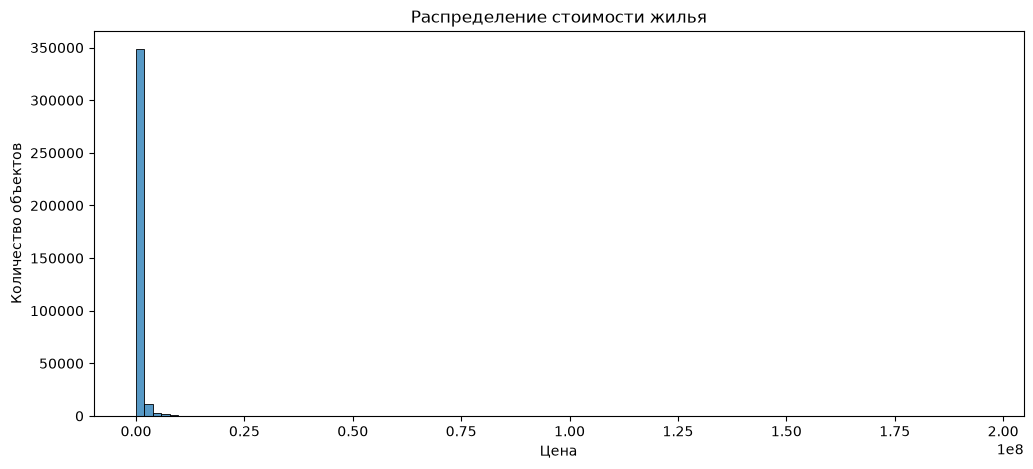

In [17]:
plt.figure(figsize=(12, 5))
sns.histplot(df["price"], bins=100)
plt.title("Распределение стоимости жилья")
plt.xlabel("Цена")
plt.ylabel("Количество объектов")
plt.show()

Данный график не информативен. Однако уже точно можно сделать вывод, что необходимо применять логарифмирование целевого признака.

Забегая вперёд следует сказать, что при работе над проектом было выявлено, что наибольшие ошибки наблюдаются в сегменте до $100 тыс (были получены значения MAPE 104.4%). Это объясняется малой представленностью таких объектов в обучающей выборке (8% теста) и высокой дисперсией цен. Поэтому принято решение отсечь нижнюю часть данных на уровне 50000.

In [18]:
initial_len = len(df)

# Отсекаем нижний мусор - первоначальный вариант, не используется.
#lower_limit = df['price'].quantile(0.005)
#df = df[df['price'] >= lower_limit]

# Абсолютная нижняя граница
LOWER_ABS = 50_000
df = df[df['price'] >= LOWER_ABS]

print(f"Удалено строк: {initial_len - len(df)}")
print(f"Осталось строк: {len(df)}")

Удалено строк: 24299
Осталось строк: 342701


Отсечём верхнюю часть данных на уровне 99-го процентиля:

In [ ]:
initial_len = len(df)

# Отсекаем верхние выбросы (оставляем до 99-го процентиля)
upper_limit = df['price'].quantile(0.99)
df = df[df['price'] <= upper_limit]

print(f"Удалено строк: {initial_len - len(df)}")
print(f"Осталось строк: {len(df)}")

Удалено строк: 3427
Осталось строк: 339274


Создадим новый признак - логарифмированная цена:

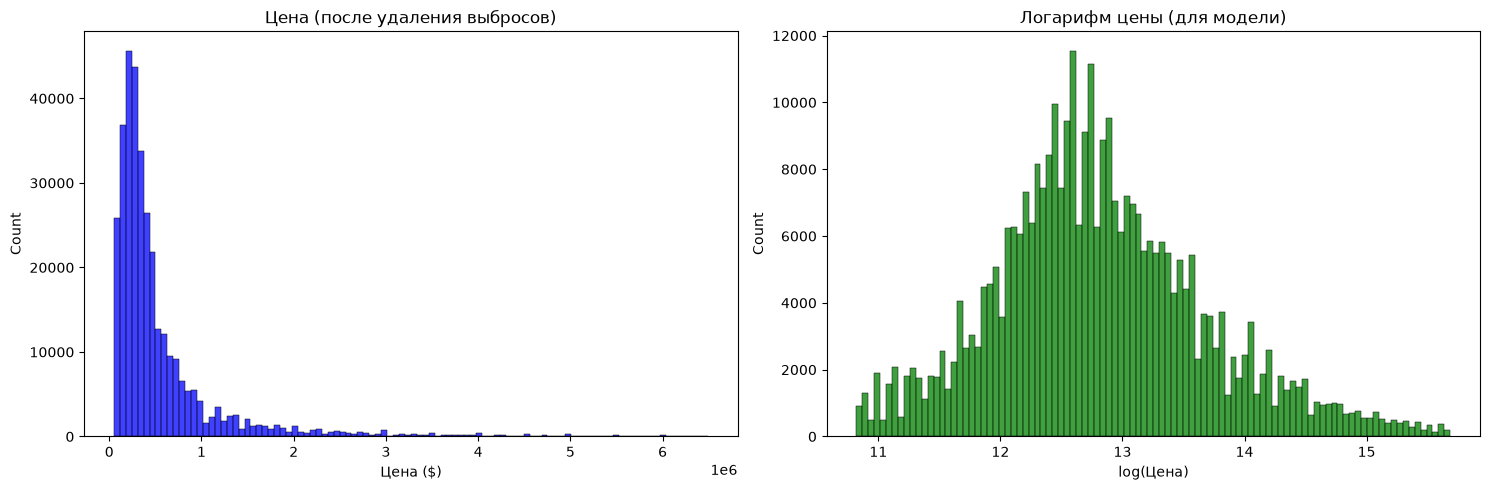

In [20]:
# Создаем логарифмированную версию цены
df['price_log'] = np.log1p(df['price'])

# Смотрим на результат
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График обычной цены
sns.histplot(df['price'], bins=100, ax=axes[0], color='blue')
axes[0].set_title('Цена (после удаления выбросов)')
axes[0].set_xlabel('Цена ($)')

# График логарифма цены
sns.histplot(df['price_log'], bins=100, ax=axes[1], color='green')
axes[1].set_title('Логарифм цены (для модели)')
axes[1].set_xlabel('log(Цена)')

plt.tight_layout()
plt.show()

In [21]:
print("\nСтатистика после очистки:")
print(df['price_log'].describe())


Статистика после очистки:
count     339274.0
mean     12.811437
std       0.868044
min      10.819798
25%      12.254868
50%       12.73641
75%       13.30452
max      15.685773
Name: price_log, dtype: Float64


Потеряли <10% записей.

Среднее (12.73) ≈ Медиана (12.81) — разница почти нулевая. Распределение стало симметричным.

Стандартное отклонение (0.86) — компактное, без раздутых хвостов.

Min (10.82) = expm1(10.82) ≈ $50 000 (это наша заявленная нижняя граница после очистки).

Max (15.68) = expm1(15.68) ≈ $6 452 639 (наш верхний самый дорогой объект).

Столбцы target и price теперь можно пометить на удаление

In [25]:
features_to_drop = add_to_drop_list("target", features_to_drop)
features_to_drop = add_to_drop_list("price", features_to_drop)

[OK] Признак 'target' добавлен в список на удаление.
[OK] Признак 'price' добавлен в список на удаление.


### <center> 4.2 Работа с признаком Status

Оценим количество пропусков и самые частые значения признака:

In [26]:
print(df["status"].isna().sum())
print(df["status"].value_counts(dropna=False).head(10))

37940
status
for sale                     137343
Active                        94275
For sale                      41960
NaN                           37940
New construction               5396
foreclosure                    4354
Pending                        4196
Pre-foreclosure                1914
P                              1483
Pre-foreclosure / auction      1211
Name: count, dtype: int64


37 940 строки ≈ 11% датасета. Пометим их как 'unknown'

Создадим функцию для парсинга статуса и его группировки в более крупные значения.

In [27]:
# Функция парсинга признака Status
def categorize_status(value):
    if pd.isna(value):
        return "unknown"

    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)

    if value in {"", "nan", "none"}:
        return "unknown"

    # Статусы, связанные с продажей
    if "sold" in value or "recently sold" in value:
        return "sold"

    # Аренда
    if (
        "for rent" in value
        or "apartment for rent" in value
        or "condo for rent" in value
        or "lease/purchase" in value
    ):
        return "rent"

    # Сначала специальные категории
    if "pre-foreclosure" in value:
        return "pre_foreclosure"

    if "foreclosure" in value or "foreclosed" in value:
        return "foreclosure"

    if "auction" in value:
        return "auction"

    if "new construction" in value:
        return "new_construction"

    if "coming soon" in value:
        return "coming_soon"

    # Составные статусы сделки
    if "contingent" in value or "contingency" in value:
        return "contingent"

    if "pending" in value or value == "P":
        return "pending"

    if "under contract" in value:
        return "under_contract"

    if "backup" in value or "back up" in value:
        return "backup"

    # Основные активные объявления
    if value in {"for sale", "active", "a active"}:
        return "active"

    if "reactivated" in value or "re-activated" in value:
        return "active"

    if value == "new":
        return "new"

    if "price change" in value:
        return "price_change"

    if "back on market" in value:
        return "back_on_market"

    return "other"


In [ ]:
# Применим функцию, создав новый признак
df["status_category"] = df["status"].apply(categorize_status)

Посмотрим на результат парсинга:

In [29]:
status_summary = (
    df["status_category"]
    .value_counts(dropna=False)
    .to_frame("count")
)

status_summary["percent"] = (
    status_summary["count"] / len(df) * 100
).round(2)

status_summary

,count,percent
status_category,,
active,273903,80.73
unknown,37940,11.18
new_construction,5396,1.59
foreclosure,4857,1.43
pending,4822,1.42
under_contract,3620,1.07
pre_foreclosure,3125,0.92
other,1813,0.53
auction,1288,0.38


«Признак status отражает стадию жизненного цикла сделки, а не характеристики объекта, и напрямую коррелирует с целевой переменной: статусы pending / under_contract соответствуют уже согласованной цене, а foreclosure / auction — цене принудительной продажи. Использование таких статусов в обучении привело бы к утечке данных и завышению метрик на тесте.

Поэтому статусы были разделены на следующие категории:
- статусы со согласованной ценой (~3% выборки) - будут удалены
- статусы с иной природой ценообразования, включая unknown (~13.6%) - будут удалены
- оставшиеся статусы (active, new, new_construction, coming_soon) объединены в единую категорию active — это целевая аудитория агентства: объекты с запрашиваемой рыночной ценой.

In [30]:
print("До фильтрации:", len(df))

# Разделяем категории
KEEP_AS_FOR_SALE = {'active', 'new', 'new_construction', 'coming_soon'}
DROP_LEAKAGE = {'pending', 'under_contract', 'contingent', 'backup',
                'price_change', 'back_on_market'}
DROP_OTHER_MARKET = {'foreclosure', 'pre_foreclosure', 'auction',
                     'rent', 'other', 'unknown'}

# Удаляем утечку и другой рынок
drop_set = DROP_LEAKAGE | DROP_OTHER_MARKET
initial_len = len(df)
df = df[~df['status_category'].isin(drop_set)].copy()
print(f"Удалено: {initial_len - len(df)} строк")
print(f"Осталось: {len(df)} строк")

# Объединяем "околоактивные" в одну категорию (или можно оставить как есть)
df['status_category'] = df['status_category'].replace({
    'new': 'active',
    'new_construction': 'active',
    'coming_soon': 'active',
})

# Проверка
print("\nИтоговое распределение status_category:")
print(df['status_category'].value_counts())

До фильтрации: 339274
Удалено: 59182 строк
Осталось: 280092 строк

Итоговое распределение status_category:
status_category
active    280092
Name: count, dtype: int64


в колонке status_category останется одно значение active. Значит, колонку можно удалить — она больше не несёт информации

In [31]:
features_to_drop = add_to_drop_list("status_category", features_to_drop)
features_to_drop = add_to_drop_list("status", features_to_drop)

[OK] Признак 'status_category' добавлен в список на удаление.
[OK] Признак 'status' добавлен в список на удаление.


### <center> 4.3 Работа с sqft, beds, baths, stories

#### <center> 4.3.1 Площадь (sqft)

Напишем функцию для парсинга площади

In [32]:
def parse_area(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip()

    if text in MISSING_VALUES:
        return np.nan

    text = text.replace(",", "")

    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    numbers = [float(number) for number in numbers]

    # Для диапазона, например 1200-1500,
    # используем среднее значение
    return np.mean(numbers)

In [ ]:
# Применим функцию, создав новый признак
df["area_sqft"] = df["sqft"].apply(parse_area)

Оценим правильность парсинга

In [34]:
df[
    ["sqft", "area_sqft"]
].drop_duplicates().head(30)

,sqft,area_sqft
0,2900,2900.0
1,"1,947 sqft",1947.0
2,"3,000 sqft",3000.0
3,"6,457 sqft",6457.0
5,897 sqft,897.0
6,"1,507",1507.0
7,NaN,NaN
8,3588,3588.0
10,"1,300 sqft",1300.0
11,"3,130",3130.0


Парсинг произведен корректно.

In [35]:
print("--- Статистика по площади (area) ---")
print(df['area_sqft'].describe())

print("\n--- Топ-10 самых больших площадей ---")
print(df['area_sqft'].nlargest(10))

print("\n--- Топ-10 самых маленьких площадей ---")
print(df['area_sqft'].nsmallest(10))

# Проверим, сколько домов с площадью больше 20 000 кв. футов
print(f"\nДомов с площадью > 20 000 кв. футов: {len(df[df['area_sqft'] > 20000])}")

--- Статистика по площади (area) ---
count    2.545850e+05
mean     4.924674e+03
std      9.054543e+05
min      0.000000e+00
25%      1.280000e+03
50%      1.838000e+03
75%      2.637000e+03
max      4.566025e+08
Name: area_sqft, dtype: float64

--- Топ-10 самых больших площадей ---
366356    456602479.0
72235       7078574.0
138297      5728968.0
50846       4356000.0
182319      4356000.0
226024      2807917.0
345273      2807917.0
227512      2613600.0
36421       2585006.0
246876      2585006.0
Name: area_sqft, dtype: float64

--- Топ-10 самых маленьких площадей ---
48     0.0
135    0.0
261    0.0
332    0.0
487    0.0
605    0.0
764    0.0
765    0.0
804    0.0
884    0.0
Name: area_sqft, dtype: float64

Домов с площадью > 20 000 кв. футов: 1407


456 602 479 кв. футов — это больше 40 квадратных километра. Видимо это либо ошибка парсера (он склеил цену и площадь, например), либо это огромный земельный участок, площадь которого записали в поле sqft.

0 кв. футов — это либо земля (участок), либо данные, где площадь не была указана, и парсер вытащил 0.

Медиана = 1838 кв. футов — это типичный размер для США (средний дом ~1600-1800 кв. футов). Значит, в целом парсер работает правильно.

50% объектов находятся в узком нормальном диапазоне.

Дома с площадью > 20 000 кв. футов — это 0.4% от выборки. Это могут быть реальные особняки (мега-дома), но чаще — ошибки.

Нам нужно сделать фильтрацию по разумным границам.
В США нормальный жилой дом редко превышает 20 000 кв. футов (это уже очень большой особняк, ~1850 кв. метров). Всё, что больше — это либо склады, либо ошибки.

In [36]:
initial_len = len(df)

# Убираем нули и слишком маленькие площади (меньше 10 кв. футов - это не дом)
mask_tiny = df['area_sqft'] < 10
df.loc[mask_tiny, 'area_sqft'] = np.nan

# Отсекаем сверхбольшие аномалии (оставляем до 20 000 кв. футов и nan, чтобы их случайно не удалило)
df = df[(df['area_sqft'] <= 20000) | df['area_sqft'].isna()]

print(f"Удалено строк (аномалии площади): {initial_len - len(df)}")
print(f"Осталось строк: {len(df)}")

# Заполняем пропуски медианой по типу недвижимости
df['area_sqft'] = df.groupby('propertyType')['area_sqft'].transform(
    lambda x: x.fillna(x.median())
)

# Если остались пропуски (если propertyType был NaN), заполняем общей медианой
df['area_sqft'] = df['area_sqft'].fillna(df['area_sqft'].median())

# Проверяем итог
print("\n--- Новая статистика по площади ---")
print(df['area_sqft'].describe())
print(f"\nОсталось пропусков: {df['area_sqft'].isnull().sum()}")

Удалено строк (аномалии площади): 1407
Осталось строк: 278685

--- Новая статистика по площади ---
count    278685.000000
mean       2124.092240
std        1284.838104
min          10.000000
25%        1415.000000
50%        1800.000000
75%        2455.000000
max       20000.000000
Name: area_sqft, dtype: float64

Осталось пропусков: 0


In [37]:
# Оценим результат
analyze_series(df['area_sqft'])

=== area_sqft ===
Всего строк:          278685
NaN:                  0
Нули:                 0
Min / Max:            10.0 / 20000.0


Пропусков в итоговых данных нет.

Исходный признак больше не нужен

In [38]:
features_to_drop = add_to_drop_list("sqft", features_to_drop)

[OK] Признак 'sqft' добавлен в список на удаление.


#### <center> 4.3.2 Спальни

Напишем функцию для парсинга количества спален

In [39]:
def parse_beds(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip()

    if text in MISSING_VALUES:
        return np.nan

    # Это не количество спален
    if re.search(r"\bacres?\b|\bsq\.?\s*ft\b|\bsqft\b|\bsquare feet\b", text):
        return np.nan

    # Студия — 0 спален
    if "studio" in text:
        return 0.0

    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    # Если встретится диапазон, например 3-4 beds
    return np.mean([float(number) for number in numbers])

In [40]:
# Применяем функцию
df["beds_num"] = df["beds"].apply(parse_beds)

Оценим результат парсинга:

In [ ]:
df[
    ["beds", "beds_num"]
].drop_duplicates().head(30)

,beds,beds_num
0,4,4.0
1,3 Beds,3.0
3,5 Beds,5.0
5,2 Beds,2.0
6,NaN,NaN
8,3,3.0
12,4 Beds,4.0
13,3 bd,3.0
16,Baths,NaN
20,4 bd,4.0


Видно, что парсер сработал корректно

Статистика по признаку

In [42]:
numeric_features = [
    "beds_num"
]

numeric_summary = pd.DataFrame({
    "missing_count": df[numeric_features].isna().sum(),
    "missing_percent": (
        df[numeric_features].isna().mean() * 100
    ).round(2)
})

numeric_summary

,missing_count,missing_percent
beds_num,86547,31.06


In [43]:
print("--- Статистика по спальням ---")
print(df['beds_num'].describe())

print("\n--- Топ-10 значений beds ---")
print(df['beds_num'].value_counts().head(10))

# Проверим, сколько домов с 0 спален (студии + ошибки)
print(f"\nДомов с 0 спален: {len(df[df['beds_num'] == 0])}")

print(f"\nДомов с 10+ спален: {len(df[df['beds_num'] > 10])}")

--- Статистика по спальням ---
count    192138.000000
mean          3.409065
std           1.860352
min           0.000000
25%           3.000000
50%           3.000000
75%           4.000000
max         364.400000
Name: beds_num, dtype: float64

--- Топ-10 значений beds ---
beds_num
3.0    76228
4.0    50819
2.0    36160
5.0    16798
6.0     4988
1.0     2922
7.0     1372
8.0      979
0.0      657
9.0      392
Name: count, dtype: int64

Домов с 0 спален: 657

Домов с 10+ спален: 594


Медиана = 3.0 (идеально для США).

Среднее = 3.33 (близко к медиане, значит, распределение нормальное).

Максимум = 364.4 — это ошибка парсинга (парсер склеил несколько чисел, например, из строки "3 beds, 2 baths, 364 sqft").

1013 домов с 0 спален — это студии (нормально) или ошибки.



Очистим данные. Заполним пропуски медианой по типу объекта. Удалим записи с количеством спален больше 15.

In [44]:
# Заполняем пропуски (NaN исчезают)
df['beds_num'] = df.groupby('propertyType')['beds_num'].transform(
    lambda x: x.fillna(x.median())
)
df['beds_num'] = df['beds_num'].fillna(df['beds_num'].median())

# фильтруем аномалии (NaN уже нет, удалятся только > 15)
initial_len = len(df)
df = df[(df['beds_num'] >= 0) & (df['beds_num'] <= 15)]
print(f"Удалено аномалий: {initial_len - len(df)}") # Удалится только мусор

# Конвертируем в int
df['beds_num'] = df['beds_num'].astype(int)

Удалено аномалий: 1859


In [45]:
print(f"Осталось строк: {len(df)}")
print(f"Пропусков в beds_num: {df['beds_num'].isnull().sum()}")
print(f"Максимум спален: {df['beds_num'].max()}")

Осталось строк: 276826
Пропусков в beds_num: 0
Максимум спален: 15


In [46]:
analyze_series(df['beds_num'])

=== beds_num ===
Всего строк:          276826
NaN:                  0
Нули:                 5278
Min / Max:            0 / 15


Пропусков в данных больше нет.

Посмотрим распределение данных по количеству спален

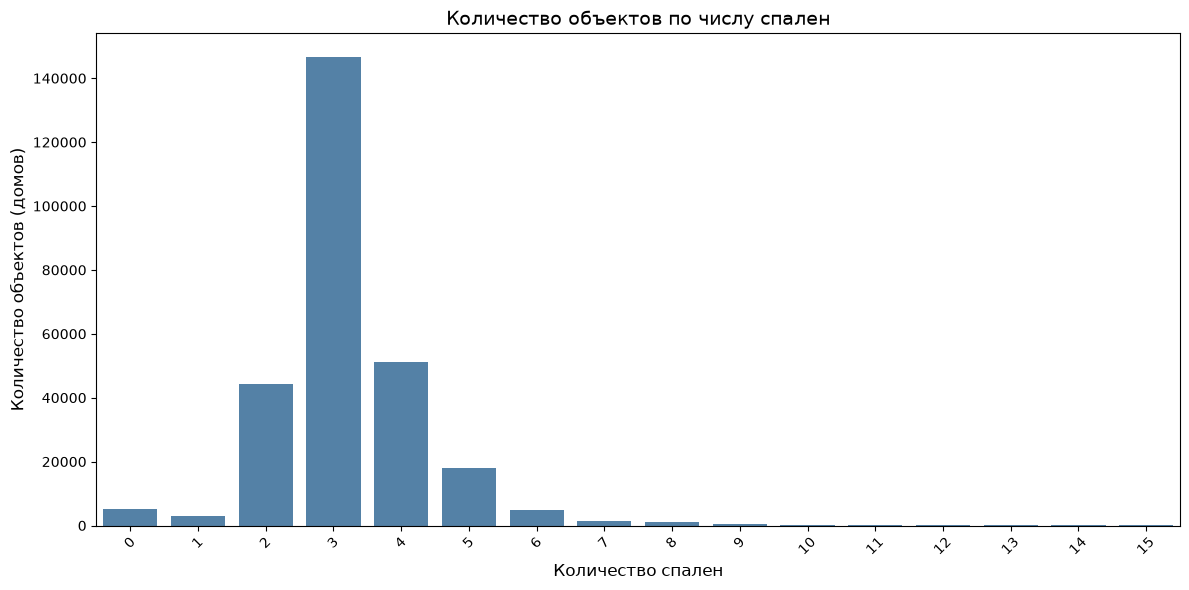

In [47]:
plt.figure(figsize=(12, 6))

# Строим countplot (считает частоту каждого значения)
sns.countplot(x='beds_num', data=df, color='steelblue')

plt.title('Количество объектов по числу спален', fontsize=14)
plt.xlabel('Количество спален', fontsize=12)
plt.ylabel('Количество объектов (домов)', fontsize=12)

# Поворачиваем подписи, если их много (чтобы не наезжали друг на друга)
plt.xticks(rotation=45) 

plt.tight_layout()
plt.show()

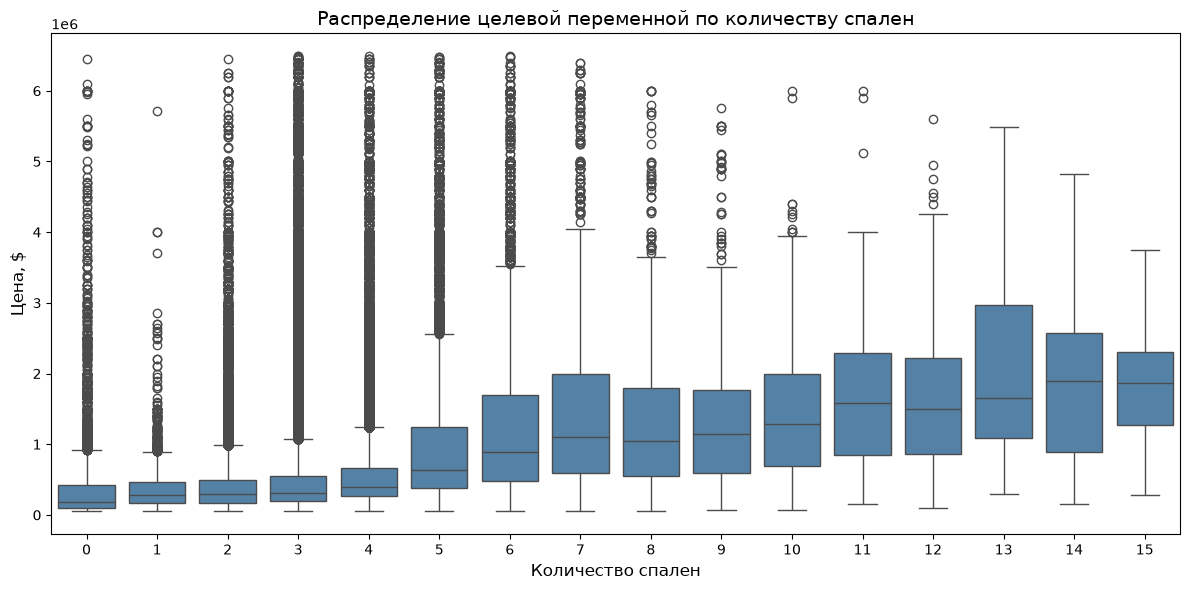

In [49]:
# Настраиваем размер графика
plt.figure(figsize=(12, 6))

# Строим боксплот
sns.boxplot(x='beds_num', y='price', data=df, color='steelblue')

# Добавляем заголовок и подписи
plt.title('Распределение целевой переменной по количеству спален', fontsize=14)
plt.xlabel('Количество спален', fontsize=12)
plt.ylabel('Цена, $', fontsize=12)

plt.tight_layout()
plt.show()

На основании графиков можно сделать несколько выводов:

1. **Распределение цен**: Цены на объекты с разным количеством спальных комнат имеют перекрывающиеся диапазоны, что указывает на отсутствие чёткой зависимости цены от количества спальных комнат.
2. **Медианные значения**: Медианные значения схожи для различных категорий, что может указывать на то, что медианная цена не сильно отличается между объектами с большим количеством спален.
3. **Разброс цен**: Графики показывают разброс цен в каждой категории.

Исходный признак пометим на удаление

In [50]:
features_to_drop = add_to_drop_list("beds", features_to_drop)

[OK] Признак 'beds' добавлен в список на удаление.


#### <center> 4.3.3 Ванные комнаты

Функция парсинга:

In [51]:
def parse_baths(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip()

    if text in MISSING_VALUES:
        return np.nan

    text = re.sub(r"(?<=\d),(?=\d)", ".", text)

    # Ищем десятичные числа или диапазоны
    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    numbers = [float(number) for number in numbers]

    return np.mean(numbers)

Применяем функцию:

In [52]:
df["baths_num"] = df["baths"].apply(parse_baths)

Оценим парсинг

In [53]:
df[
    ["baths", "baths_num"]
].drop_duplicates().head(30)

,baths,baths_num
0,3.5,3.50
1,3 Baths,3.00
2,2 Baths,2.00
3,8 Baths,8.00
5,NaN,NaN
8,2,2.00
13,Bathrooms: 2,2.00
16,"1,750",1.75
18,4 Baths,4.00
20,2 ba,2.00


In [54]:
numeric_features = [
    "baths_num"
]

numeric_summary = pd.DataFrame({
    "missing_count": df[numeric_features].isna().sum(),
    "missing_percent": (
        df[numeric_features].isna().mean() * 100
    ).round(2)
})

numeric_summary

,missing_count,missing_percent
baths_num,79678,28.78


In [55]:
print("--- Статистика по ванным ---")
print(df['baths_num'].describe())

print("\n--- Топ-10 значений baths ---")
print(df['baths_num'].value_counts().head(10))

# Проверим, сколько домов с 0 спален (студии + ошибки)
print(f"\nДомов с 0 ванными: {len(df[df['baths_num'] == 0])}")

--- Статистика по ванным ---
count    197148.000000
mean          3.610199
std          25.154986
min           0.000000
25%           2.000000
50%           2.500000
75%           3.000000
max         750.000000
Name: baths_num, dtype: float64

--- Топ-10 значений baths ---
baths_num
2.00    75759
3.00    51943
4.00    20645
1.00     9800
2.50     9009
5.00     7501
3.50     4435
1.50     3418
6.00     3361
1.75     1706
Name: count, dtype: int64

Домов с 0 ванными: 1124


Среднее = 2.5, а медиана = 3.6. Разрыва практически нет.

Максимум = 750 — это не ванные, это площадь (кв. футы) или цена, которые парсер вытащил из текста.

Заполним пропуски медианой по типу недвижимости и удалим явные аномалии (количество ванных более 15).

In [56]:
# Заполняем пропуски медианой по типу недвижимости
df['baths_num'] = df.groupby('propertyType')['baths_num'].transform(
    lambda x: x.fillna(x.median())
)
df['baths_num'] = df['baths_num'].fillna(df['baths_num'].median())

# фильтруем аномалии (NaN уже нет)
# Оставляем от 0 до 15 ванных
initial_len = len(df)
df = df[(df['baths_num'] >= 0) & (df['baths_num'] <= 15)]
print(f"Удалено аномалий (ванные > 15): {initial_len - len(df)}")

# Округляем до 1 знака (чтобы убрать мусор типа 2.3333)
df['baths_num'] = df['baths_num'].round(1)

# Проверяем
print(f"Пропусков: {df['baths_num'].isnull().sum()}")
print(f"Максимум: {df['baths_num'].max()}")
print(f"Медиана: {df['baths_num'].median()}")
print(f"Среднее: {df['baths_num'].mean():.2f}")

Удалено аномалий (ванные > 15): 279
Пропусков: 0
Максимум: 15.0
Медиана: 2.0
Среднее: 2.54


In [57]:
print(f"Осталось строк: {len(df)}")
print(f"Пропусков в baths_num: {df['baths_num'].isnull().sum()}")
print(f"Максимум ванных комнат: {df['baths_num'].max()}")

Осталось строк: 276547
Пропусков в baths_num: 0
Максимум ванных комнат: 15.0


In [58]:
analyze_series(df['baths_num'])

=== baths_num ===
Всего строк:          276547
NaN:                  0
Нули:                 4878
Min / Max:            0.0 / 15.0


Пропусков в данных больше нет. Посмотрим на распределение значений:

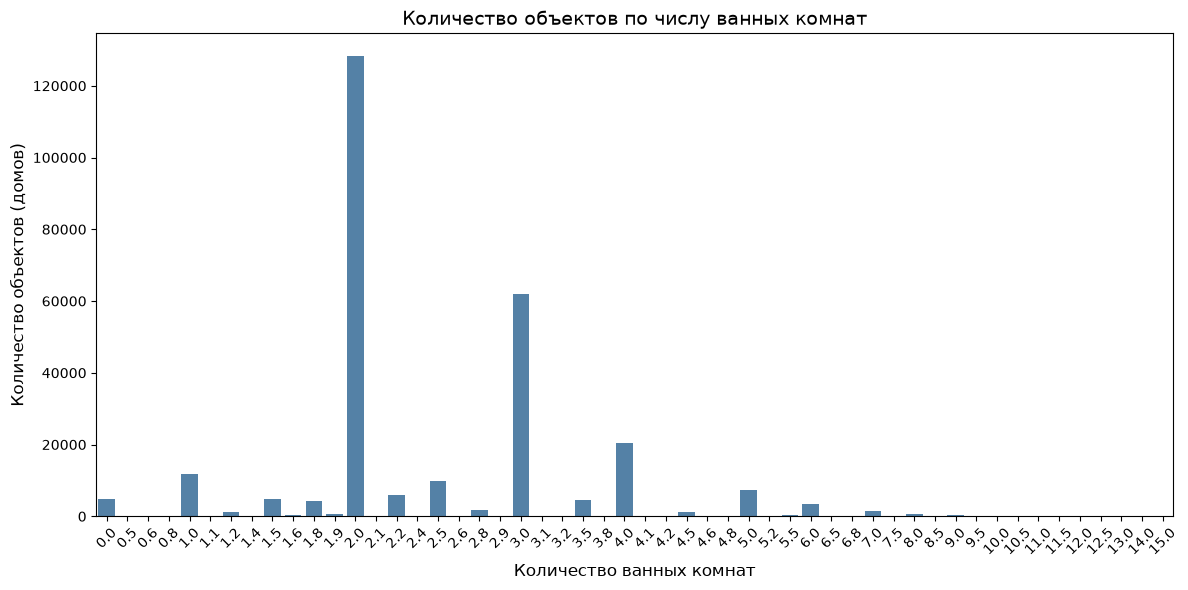

In [59]:
plt.figure(figsize=(12, 6))

# Строим countplot (считает частоту каждого значения)
sns.countplot(x='baths_num', data=df, color='steelblue')

plt.title('Количество объектов по числу ванных комнат', fontsize=14)
plt.xlabel('Количество ванных комнат', fontsize=12)
plt.ylabel('Количество объектов (домов)', fontsize=12)

# Поворачиваем подписи, если их много (чтобы не наезжали друг на друга)
plt.xticks(rotation=45) 

plt.tight_layout()
plt.show()

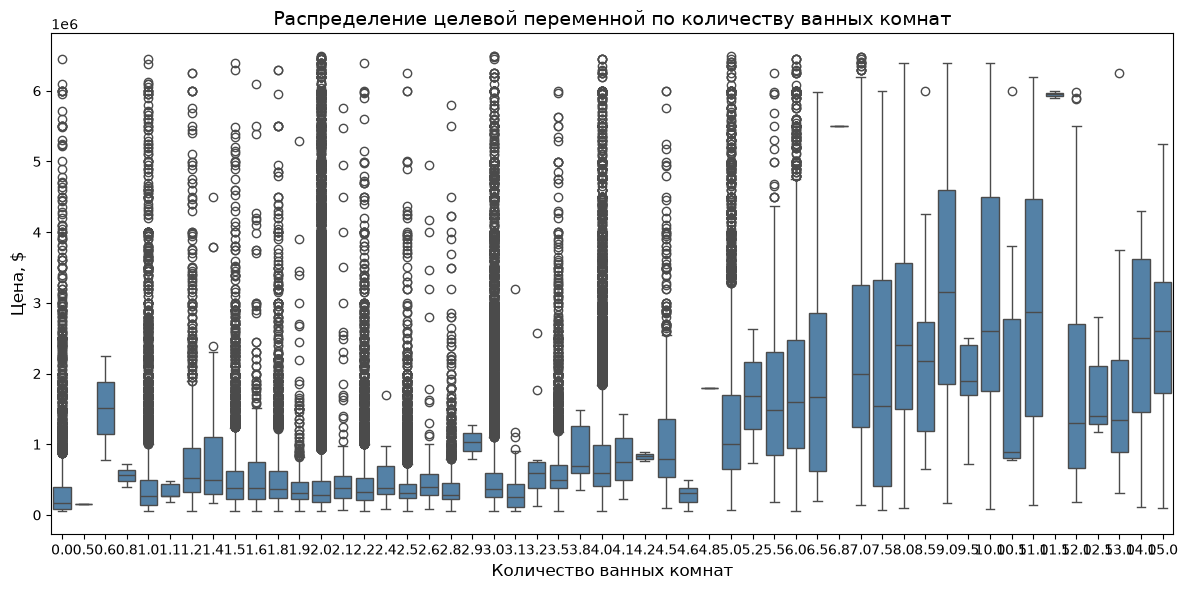

In [60]:
# Настраиваем размер графика
plt.figure(figsize=(12, 6))

# Строим боксплот
# Обратите внимание: мы строим по оригинальной цене 'price', чтобы было понятно в долларах
sns.boxplot(x='baths_num', y='price', data=df, color='steelblue')

# Добавляем заголовок и подписи
plt.title('Распределение целевой переменной по количеству ванных комнат', fontsize=14)
plt.xlabel('Количество ванных комнат', fontsize=12)
plt.ylabel('Цена, $', fontsize=12)

# Чтобы ось Y не выводила числа в научном формате (1e6), а показывала миллионы
# plt.ticklabel_format(style='plain', axis='y') 

plt.tight_layout()
plt.show()

Распределение объектов по количеству ванных комнат показало, что подавляющее большинство выборки (более 60%) составляют дома с 2 и 3 ванными комнатами. Дома с 1 ванной и студиями (0 ванных) представляют собой нижний сегмент рынка, тогда как объекты с 5+ ванными комнатами — это редкие элитные особняки, формирующие правый хвост распределения

Исходный признак больше не нужен

In [61]:
features_to_drop = add_to_drop_list("baths", features_to_drop)

[OK] Признак 'baths' добавлен в список на удаление.


#### <center> 4.3.4 Этажи

Функция для парсинга количества этажей:

In [62]:
def parse_stories(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip()

    if text in MISSING_VALUES:
        return np.nan

    word_to_number = {
        "one": 1,
        "two": 2,
        "three": 3,
        "four": 4,
        "five": 5
    }

    for word, number in word_to_number.items():
        if re.search(rf"\b{word}\b", text):
            return float(number)

    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    return float(numbers[0])

Применяем функцию

In [63]:
df["stories_num"] = df["stories"].apply(parse_stories)

Оцениваем парсинг

In [64]:
df[
    ["stories", "stories_num"]
].drop_duplicates().head(30)

,stories,stories_num
0,NaN,NaN
1,2.0,2.0
2,1.0,1.0
3,3.0,3.0
6,One,1.0
11,2,2.0
22,Multi/Split,NaN
29,4.0,4.0
31,0.0,0.0
36,0,0.0


In [65]:
print("--- Статистика по этажам ---")
print(df['stories_num'].describe())

print("\n--- Топ-10 значений stories ---")
print(df['stories_num'].value_counts().head(10))

# Проверим, сколько домов с 0 спален (студии + ошибки)
print(f"\nДомов с 0 этажами: {len(df[df['stories_num'] == 0])}")

--- Статистика по этажам ---
count    163701.000000
mean          1.950509
std           4.581811
min           0.000000
25%           1.000000
50%           2.000000
75%           2.000000
max        1120.000000
Name: stories_num, dtype: float64

--- Топ-10 значений stories ---
stories_num
1.0    71432
2.0    60763
3.0    14495
0.0     7436
9.0     2857
4.0     2470
1.5      869
6.0      729
5.0      596
7.0      303
Name: count, dtype: int64

Домов с 0 этажами: 7436


In [66]:
print("\n--- Топ-10 самых высоких объектов ---")
print(df['stories_num'].nlargest(20))


--- Топ-10 самых высоких объектов ---
216845    1120.0
308015    1002.0
179711      91.0
281418      91.0
352115      91.0
172942      82.0
328780      80.0
29818       78.0
57245       78.0
105999      78.0
191780      77.0
138586      75.0
173853      75.0
205268      70.0
305102      70.0
326551      70.0
188609      66.0
189929      66.0
246051      66.0
326535      66.0
Name: stories_num, dtype: float64


Признак stories_num содержит аномальное значение 1120 этажей (ошибка парсинга).

Значения 0 (7 623 объекта) были интерпретированы как одноэтажные дома (дом не может не иметь этажей) и будут заменены на 1.

После этого применим фильтрацию по диапазону [1, 10]. Пропуски заполним медианой по типу недвижимости

In [67]:
# Заменяем 0 на 1 (дом не может быть без этажей)
df['stories_num'] = df['stories_num'].replace(0, 1)

# Заполняем пропуски медианой по типу недвижимости
df['stories_num'] = df.groupby('propertyType')['stories_num'].transform(
    lambda x: x.fillna(x.median())
)
df['stories_num'] = df['stories_num'].fillna(df['stories_num'].median())

# фильтруем аномалии (после заполнения, чтобы не удалить NaN)
initial_len = len(df)
df = df[(df['stories_num'] >= 1) & (df['stories_num'] <= 15)]
print(f"Удалено аномалий (этажи): {initial_len - len(df)}")

# Проверяем
print(f"\nПропусков в stories_num: {df['stories_num'].isnull().sum()}")
print(f"Максимум этажей: {df['stories_num'].max()}")
print(f"Медиана: {df['stories_num'].median()}")
print(f"Тип данных: {df['stories_num'].dtype}")

Удалено аномалий (этажи): 918

Пропусков в stories_num: 0
Максимум этажей: 15.0
Медиана: 1.5
Тип данных: float64


In [68]:
analyze_series(df['stories_num'])

=== stories_num ===
Всего строк:          275629
NaN:                  0
Нули:                 0
Min / Max:            1.0 / 15.0


Пропусков нет. Оценим распределение:

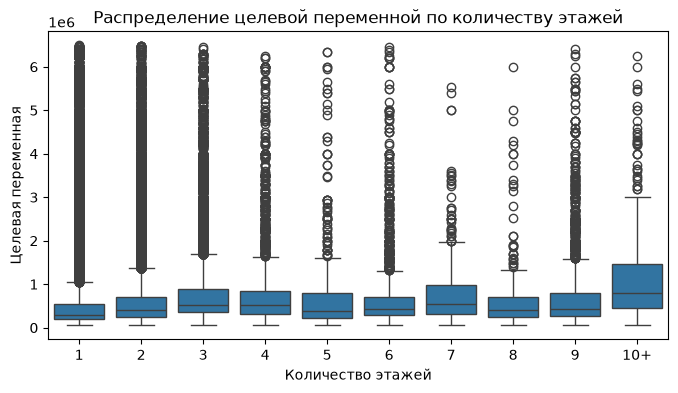

In [69]:
# Группировка значений больше 10
stories_grouped = df['stories_num'].apply(lambda x: '10+' if x > 10 else str(int(x)))

# Указываем желаемый порядок категорий от 0 до 10 и 10+
desired_order = [str(i) for i in range(1, 10)] + ['10+']

# Визуализация boxplot
plt.figure(figsize=(8, 4))
sns.boxplot(x=stories_grouped, y=df['price'], order=desired_order)
plt.title('Распределение целевой переменной по количеству этажей')
plt.xlabel('Количество этажей')
plt.ylabel('Целевая переменная')
plt.show()

Анализ зависимости цены от количества этажей (boxplot) показал, что данный признак обладает низкой предсказательной силой в масштабах страны: медианная стоимость домов с 1–9 этажами находится примерно на одном уровне. Однако выделяется категория "10+ этажей", где медиана и межквартильный размах значительно выше, что объясняется наличием элитных пентхаусов и огромных особняков.

Пометим на удаление исходный признак

In [70]:
features_to_drop = add_to_drop_list("stories", features_to_drop)

[OK] Признак 'stories' добавлен в список на удаление.


Проведем проверку после преобразований по разделу:

In [71]:
numeric_features = [
    "area_sqft",
    "beds_num",
    "baths_num",
    "stories_num"
]

numeric_summary = pd.DataFrame({
    "missing_count": df[numeric_features].isna().sum(),
    "missing_percent": (
        df[numeric_features].isna().mean() * 100
    ).round(2)
})

numeric_summary

,missing_count,missing_percent
area_sqft,0,0.0
beds_num,0,0.0
baths_num,0,0.0
stories_num,0,0.0


Пропусков в данных больше нет.

### <center> 4.4 Работа с признаком homeFacts

#### <center> 4.4.1 Десериализация homeFacts

Посмотрим, какие признаки содержит поле homeFacts

In [72]:
# Десериализуем содержимое признака 'homeFacts'
df['homeFacts'] = df['homeFacts'].apply(ast.literal_eval)

# Извлекаем значения по ключу 'factLabel'
fact_labels = [item['factLabel'] for item in df['homeFacts'][0]['atAGlanceFacts']]
# Выводим заголовки списком
print(fact_labels)

['Year built', 'Remodeled year', 'Heating', 'Cooling', 'Parking', 'lotsize', 'Price/sqft']


In [73]:
# Создадим новые признаки на основе десериализованных значений
df['year_built'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][0]['factValue'])
df['remodeled_year'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][1]['factValue'])
df['heating'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][2]['factValue'])
df['cooling'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][3]['factValue'])
df['parking'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][4]['factValue'])
df['lotsize'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][5]['factValue'])
df['price_sqft'] = df['homeFacts'].apply(lambda x: x['atAGlanceFacts'][6]['factValue'])

Необходимо обработать полученные признаки следующим образом:
- Year built	числовой -	преобразовать в год
- Remodeled year	числовой -	преобразовать в год
- Heating	категориальный	- нормализовать строки
- Cooling	категориальный	- нормализовать строки
- Parking	категориальный
- lotsize	числовой -	привести к единой единице
- Price/sqft	потенциальная утечка -	не использовать как признак

Удаляем для избегания утечки

In [74]:
features_to_drop = add_to_drop_list("price_sqft", features_to_drop)

[OK] Признак 'price_sqft' добавлен в список на удаление.


#### <center> 4.4.2 Обработка года постройки

Преобразуем строки в числовой формат

In [75]:
df["year_built"] = pd.to_numeric(
    df["year_built"],
    errors="coerce"
)

Оценим признак

In [76]:
print(df["year_built"].describe())
print(
    df["year_built"]
    .value_counts(dropna=False)
    .sort_index()
    .head(30)
)

count    2.389730e+05
mean     4.688623e+06
std      1.620020e+09
min      1.000000e+00
25%      1.957000e+03
50%      1.986000e+03
75%      2.007000e+03
max      5.599906e+11
Name: year_built, dtype: float64
year_built
1.0        1
1019.0     1
1057.0     1
1060.0     1
1700.0     1
1703.0     2
1740.0     1
1750.0     2
1788.0     1
1790.0     2
1794.0     1
1795.0     1
1796.0     2
1799.0     2
1800.0    21
1803.0     1
1804.0     1
1805.0     1
1807.0     1
1808.0     1
1809.0     1
1810.0     4
1811.0     1
1812.0     1
1815.0     3
1816.0     3
1817.0     2
1818.0     2
1820.0    11
1822.0     2
Name: count, dtype: int64


In [78]:
analyze_series(df['year_built'])

=== year_built ===
Всего строк:          275629
NaN:                  36656
Нули:                 0
Min / Max:            1.0 / 559990649990.0


Удалим аномальные значения и заполним пропуски медианными значениями

In [79]:
s = df['year_built']

print(f"< 1600:               {(s < 1600).sum()}")
print(f"> 2026:               {(s > 2026).sum()}")
print(f"Валидных (1600–2026): {s.between(1600, 2026).sum()}")

< 1600:               4
> 2026:               2
Валидных (1600–2026): 238967


In [ ]:
invalid_year_built = (
    (df["year_built"] < 1600) |
    (df["year_built"] > 2026)
)

6


In [81]:
df.loc[invalid_year_built, "year_built"] = np.nan

In [82]:
# Медиана по типу недвижимости (только по валидным годам)
median_by_type = df.groupby('propertyType')['year_built'].transform('median')
df['year_built'] = df['year_built'].fillna(median_by_type)

# Fallback, если в каком-то типе вообще нет данных
df['year_built'] = df['year_built'].fillna(df['year_built'].median())

Целесообразно создать новый признак - возраст объекта

In [83]:
df["property_age"] = 2026 - df["year_built"]

In [84]:
analyze_series(df['property_age'])

=== property_age ===
Всего строк:          275629
NaN:                  0
Нули:                 0
Min / Max:            1.0 / 326.0


#### <center> 4.4.3 Обработка Remodeled year

Преобразуем в числовой тип

In [86]:
df["remodeled_year"] = pd.to_numeric(
    df["remodeled_year"],
    errors="coerce"
)

In [87]:
print(df["remodeled_year"].describe())
print(
    df["remodeled_year"]
    .value_counts(dropna=False)
    .sort_index()
    .head(30)
)

count    116869.000000
mean       1979.117978
std          90.203542
min           0.000000
25%        1968.000000
50%        1987.000000
75%        2004.000000
max        2021.000000
Name: remodeled_year, dtype: float64
remodeled_year
0.0       223
1111.0      1
1800.0      1
1845.0      1
1846.0      1
1853.0      1
1862.0      1
1869.0      1
1870.0      1
1874.0      1
1876.0      2
1877.0      2
1880.0      4
1883.0      2
1884.0      2
1885.0      2
1886.0      2
1887.0      2
1888.0      1
1889.0      6
1890.0     18
1891.0      4
1892.0     14
1893.0      2
1894.0      4
1895.0     14
1896.0      3
1897.0      1
1898.0      9
1899.0    297
Name: count, dtype: int64


In [88]:
analyze_series(df['remodeled_year'])

=== remodeled_year ===
Всего строк:          275629
NaN:                  158760
Нули:                 223
Min / Max:            0.0 / 2021.0


In [89]:
# Заменяем нули и невалидные годы на NaN (это не ремонт)
mask_invalid = (df['remodeled_year'] == 0) | (df['remodeled_year'] < 1600) | (df['remodeled_year'] > 2026)
print(f"Заменяем на NaN: {mask_invalid.sum()}")

df.loc[mask_invalid, 'remodeled_year'] = np.nan

# Проверка
print(f"NaN после чистки: {df['remodeled_year'].isna().sum()}")
print(f"Min / Max после чистки: {df['remodeled_year'].min():.0f} / {df['remodeled_year'].max():.0f}")

Заменяем на NaN: 224
NaN после чистки: 158984
Min / Max после чистки: 1800 / 2021


Полезно создать бинарный признак ремонта, а также возраст после ремонта:

In [90]:
# Флаг: был ли ремонт (год валиден и больше года постройки)
df['was_remodeled'] = (
    df['remodeled_year'].notna() &
    (df['remodeled_year'] > df['year_built'])   # ремонт после постройки
).astype('int8')

# Возраст ремонта — только для тех, у кого ремонт был
df['years_since_remodel'] = 2026 - df['remodeled_year']  # для NaN останется NaN

# Проверка
print(f"Доля домов с ремонтом: {df['was_remodeled'].mean() * 100:.1f}%")
print(f"Средний возраст ремонта (где был): {df['years_since_remodel'].mean():.0f} лет")
print(f"NaN в years_since_remodel: {df['years_since_remodel'].isna().sum()}")  # = 178 609

Доля домов с ремонтом: 16.9%
Средний возраст ремонта (где был): 43 лет
NaN в years_since_remodel: 158984


In [91]:
df['years_since_remodel'] = df['years_since_remodel'].fillna(
    df['years_since_remodel'].median()
)

In [92]:
analyze_series(df['years_since_remodel'])

=== years_since_remodel ===
Всего строк:          275629
NaN:                  0
Нули:                 0
Min / Max:            5.0 / 226.0


#### <center> 4.4.4 Обработка lotsize

In [93]:
print(
    df["lotsize"]
    .value_counts(dropna=False)
    .head(50)
)

lotsize
                 25391
—                22509
NaN              12544
-- sqft lot       3620
0.26 acres        1685
0.28 acres        1542
No Data           1451
0.25 acres        1426
0.27 acres        1396
0.29 acres        1336
0.34 acres        1181
0.3 acres         1049
10,000 sqft       1043
0.31 acres         977
0.32 acres         919
6,098 sqft         890
0.33 acres         833
0.35 acres         801
6,534 sqft         792
0.46 acres         781
7,405 sqft         756
0.36 acres         743
5,000 sqft         719
0.37 acres         715
8,712 sqft         680
5,227 sqft         654
4,356 sqft         651
0.38 acres         605
1 acre             596
0.4 acres          594
0.39 acres         568
8,276 sqft         556
2,500 sqft         545
0.41 acres         545
0.26 Acres         542
10,019 sqft        535
2,000 sqft         528
7,500 sqft         523
871 sqft           509
0.42 acres         500
0.43 acres         488
6,970 sqft         483
5,000 Sq. Ft.      481
3,9

Для модели нужно привести всё к одной единице, например к квадратным футам. Напишем соответствующую функцию

In [94]:
def parse_lot_size(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().strip()

    if text in MISSING_VALUES:
        return np.nan

    text = text.replace(",", "")

    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if not numbers:
        return np.nan

    number = float(numbers[0])

    if "acre" in text:
        return number * 43560

    if (
        "sqft" in text
        or "sq ft" in text
        or "square feet" in text
        or "sq. ft" in text
    ):
        return number

    return np.nan

Применим её к признаку:

In [95]:
df["lot_size_sqft"] = df["lotsize"].apply(parse_lot_size)

In [96]:
df[
    ["lotsize", "lot_size_sqft"]
].drop_duplicates().head(30)

,lotsize,lot_size_sqft
0,NaN,NaN
1,5828 sqft,5828.0
2,"8,626 sqft",8626.0
3,"8,220 sqft",8220.0
5,680 sqft,680.0
6,"4,996 Sq. Ft.",4996.0
7,"8,750 Sq. Ft.",8750.0
8,124582,NaN
10,1.73 acres,75358.8
11,"5,715 Sq. Ft.",5715.0


Оценим пропуски:

In [97]:
df.loc[
    df["lot_size_sqft"] <= 0,
    "lot_size_sqft"
] = np.nan

In [98]:
df["lot_size_sqft"].describe()

count    1.822900e+05
mean     9.418533e+04
std      8.049359e+06
min      1.000000e+00
25%      5.000000e+03
50%      7.884000e+03
75%      1.437480e+04
max      2.147484e+09
Name: lot_size_sqft, dtype: float64

In [99]:
analyze_series(df['lot_size_sqft'])

=== lot_size_sqft ===
Всего строк:          275629
NaN:                  93339
Нули:                 0
Min / Max:            1.0 / 2147483606.4


Удалим аномалии в данных.

In [100]:
# Заменяем нереалистичные значения на NaN
df.loc[(df['lot_size_sqft'] < 100) | (df['lot_size_sqft'] > 5_000_000), 'lot_size_sqft'] = np.nan

print(f"NaN после чистки: {df['lot_size_sqft'].isna().sum()}")
print(f"Min / Max: {df['lot_size_sqft'].min():.0f} / {df['lot_size_sqft'].max():.0f}")

NaN после чистки: 93720
Min / Max: 100 / 4987620


Заполним пропуски медианой по типу недвижимости

In [101]:
# Медиана по типу недвижимости (только по валидным)
median_lot_by_type = df.groupby('propertyType')['lot_size_sqft'].transform('median')
df['lot_size_sqft'] = df['lot_size_sqft'].fillna(median_lot_by_type)

# Fallback на общую медиану, если в каком-то типе нет валидных
df['lot_size_sqft'] = df['lot_size_sqft'].fillna(df['lot_size_sqft'].median())

# Проверка
print(f"NaN после заполнения: {df['lot_size_sqft'].isna().sum()}")  # 0
print(f"Медиана: {df['lot_size_sqft'].median():.0f}")
print(f"Min / Max: {df['lot_size_sqft'].min():.0f} / {df['lot_size_sqft'].max():.0f}")

NaN после заполнения: 0
Медиана: 7250
Min / Max: 100 / 4987620


In [102]:
analyze_series(df['lot_size_sqft'])

=== lot_size_sqft ===
Всего строк:          275629
NaN:                  0
Нули:                 0
Min / Max:            100.0 / 4987620.0


Оценим корреляцию значений площадей:

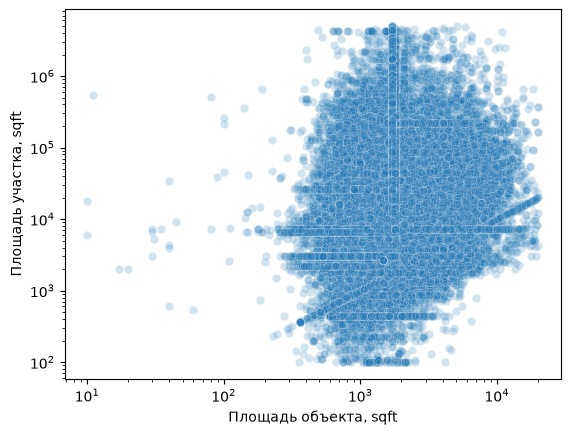

In [103]:
sns.scatterplot(
    data=df,
    x="area_sqft",
    y="lot_size_sqft",
    alpha=0.2
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Площадь объекта, sqft")
plt.ylabel("Площадь участка, sqft")
plt.show()

Видно, что линейной зависимости между площадью объекта и площадью участка в выборке почти нет. Точки образуют широкое облако, а не узкую диагональную полосу.

Что это значит
- area_sqft и lot_size_sqft несут разную информацию;
- признак lot_size_sqft не является дубликатом area_sqft;
- мультиколлинеарность между ними отсутствует;
- использовать оба признака в модели можно;
- утечки данных между ними нет.

In [104]:
# Пометим неиспользуемый признак на удаление
features_to_drop = add_to_drop_list("lotsize", features_to_drop)

[OK] Признак 'lotsize' добавлен в список на удаление.


#### <center> 4.4.5 Обработка Heating, Cooling и Parking

Сначала посмотрим частотность рассматриваемых признаков:

In [105]:
print(df["heating"].value_counts(dropna=False).head(30))

heating
Forced Air                     74900
                               72701
Forced air                     28835
Other                          20088
Central Air                     7627
Gas                             7243
Electric                        6788
Central Electric                6412
Heat Pump                       5665
Central                         5202
Central, Electric               3563
Baseboard                       3332
Wall                            2387
Electric Heat                   2367
No Data                         2058
Heating System                  1953
Heat pump                       1771
Central Air, Ceiling Fan(s)     1408
Radiant                         1314
Forced air, Heat pump           1217
Natural Gas Heat                1180
Central Electric, Zoned          855
Forced Air Heating               694
Forced Air, Natural Gas          651
Central Furnace                  639
Forced Air, Gas                  609
Gas Heat                      

In [106]:
print(df["cooling"].value_counts(dropna=False).head(30))

cooling
Central                                            121248
                                                    81627
Central Air                                         11417
Has Cooling                                          9504
None                                                 5682
Central Electric                                     4938
No Data                                              3661
Central Gas                                          3544
Wall                                                 3256
Central Heating                                      2407
Cooling System                                       1950
Central A/C (Electric), Central Heat (Gas)           1590
Central A/C                                          1568
Central A/C (Electric), Central Heat (Electric)      1297
Central, Electric                                     996
Other                                                 889
Evaporative                                           889
Electr

In [107]:
print(df["parking"].value_counts(dropna=False).head(30))

parking
                                    129813
Attached Garage                      61847
2 spaces                             14732
Detached Garage                      10694
1 space                               6816
Carport                               6549
No Data                               3967
Off Street                            3347
3 spaces                              2885
Carport, Attached Garage              2567
1                                     2506
2                                     2290
4 spaces                              1970
None                                  1869
On Street                             1135
Attached Garage, Detached Garage       968
Attached Garage, Carport               915
Off street                             857
Parking Desc                           697
0                                      692
Detached Garage, Attached Garage       545
4                                      544
6 spaces                               536
Dri

Приведем строки к единому виду:

In [108]:
for column in ["heating", "cooling", "parking"]:
    df[column] = (
        df[column]
        .astype("string")
        .str.lower()
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

Пустые и технические значения заменим на пропуски

In [109]:
for column in ["heating", "cooling", "parking"]:
    df[column] = df[column].mask(
        df[column].isin(MISSING_VALUES)
    )

In [110]:
df[
    ["heating", "cooling", "parking"]
].drop_duplicates().head(30)

,heating,cooling,parking
0,"central a/c, heat pump",<NA>,<NA>
1,<NA>,<NA>,<NA>
2,forced air,central,attached garage
3,forced air,central,detached garage
5,forced air,central,<NA>
6,"electric, heat pump",central air,<NA>
10,<NA>,<NA>,attached garage
11,central electric,central gas,<NA>
12,forced air,central,"carport, attached garage"
13,forced air,<NA>,attached garage


Создадим бинарные признаки:

In [111]:
df["has_heating"] = df["heating"].notna().astype("int8")
df["has_cooling"] = df["cooling"].notna().astype("int8")
df["has_parking"] = df["parking"].notna().astype("int8")

df[['has_heating', 'has_cooling', 'has_parking']].head(10)

,has_heating,has_cooling,has_parking
0,1,0,0
1,0,0,0
2,1,1,1
3,1,1,1
5,1,1,0
6,1,1,0
7,0,0,0
8,1,1,0
10,0,0,1
11,1,1,0


Отобразим распределение:

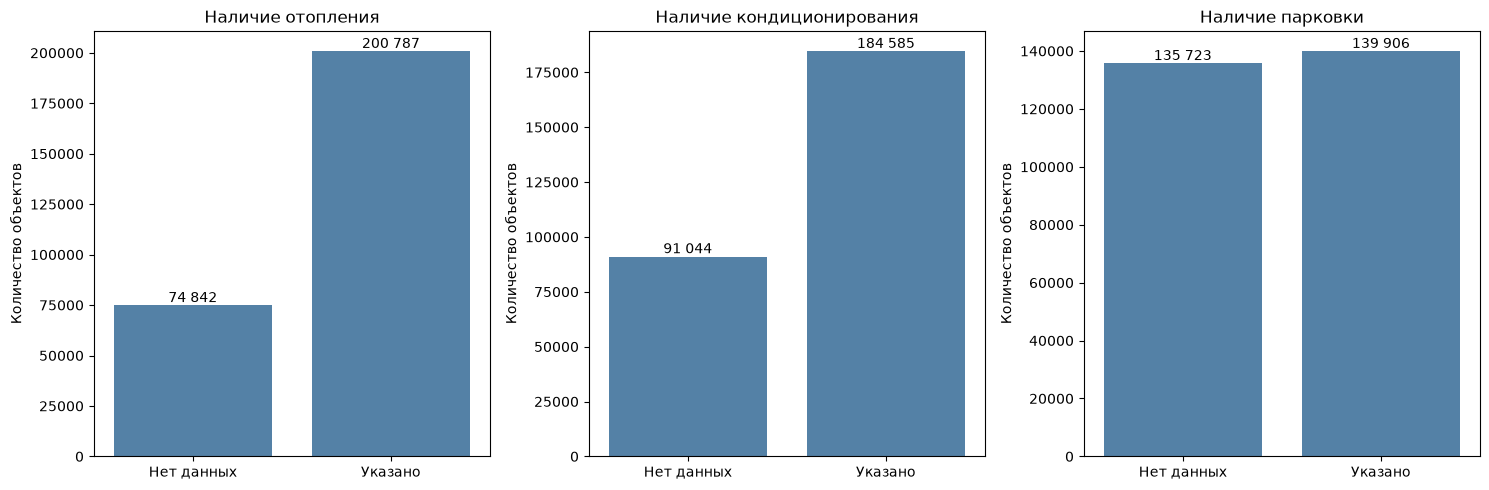

In [112]:
columns = [
    "has_heating",
    "has_cooling",
    "has_parking"
]

titles = [
    "Наличие отопления",
    "Наличие кондиционирования",
    "Наличие парковки"
]

labels = {
    0: "Нет данных",
    1: "Указано"
}

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 5)
)

for ax, column, title in zip(axes, columns, titles):
    counts = df[column].value_counts().sort_index()

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Количество объектов")

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        labels[0],
        labels[1]
    ])

    for i, value in enumerate(counts.values):
        ax.text(
            i,
            value,
            f"{value:,}".replace(",", " "),
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.show()

Удаляем временные и уже ненужные столбцы:

In [113]:
features_to_drop = add_to_drop_list(["homeFacts", 'heating', 'cooling', 'parking'], features_to_drop)

[OK] Признак 'homeFacts' добавлен в список на удаление.
[OK] Признак 'heating' добавлен в список на удаление.
[OK] Признак 'cooling' добавлен в список на удаление.
[OK] Признак 'parking' добавлен в список на удаление.


### <center> 4.5 Работа с признаком Schools

#### <center> 4.5.1 Десериализация Schools

Оценим, как выглядит признак Schools

In [119]:
print(df["schools"].head(5).to_string())
print(df["schools"].dtype)
print(df["schools"].isna().sum())

0    [{'rating': ['4', '4', '7', 'NR', '4', '7', 'N...
1    [{'rating': ['4/10', 'None/10', '4/10'], 'data...
2    [{'rating': ['8/10', '4/10', '8/10'], 'data': ...
3    [{'rating': ['9/10', '9/10', '10/10', '9/10'],...
5    [{'rating': [], 'data': {'Distance': [], 'Grad...
object
0


In [115]:
print(
    df["schools"]
    .dropna()
    .map(type)
    .value_counts()
)

schools
<class 'str'>    275629
Name: count, dtype: int64


Преобразуем строки в Python-объекты

In [116]:
def parse_schools(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    if isinstance(value, str):
        text = value.strip()

        if text in {"", "nan", "none", "null", "[]"}:
            return []

        try:
            parsed = ast.literal_eval(text)

            if isinstance(parsed, list):
                return parsed

            return []

        except (ValueError, SyntaxError):
            return []

    return []

Создадим временный распарсенный столбец:

In [117]:
df["schools_parsed"] = df["schools"].apply(parse_schools)

#### <center> 4.5.2 Обработка признака Количество школ

Преобразуем данный признак в числовой

In [120]:
df["schools_count"] = (
    df["schools_parsed"]
    .apply(len)
    .astype("int16")
)

#### <center> 4.5.3 Обработка признака Рейтинг школ

Напишем функции для парсинга рейтинга школ

In [121]:
def parse_rating(value):
    if value is None or pd.isna(value):
        return np.nan

    text = str(value).strip().lower()

    # Явно отсутствующий рейтинг
    invalid_values = {
        "",
        "none",
        "nr",
        "n/a",
        "na",
        "nan",
        "not rated",
        "not available"
    }

    if text in invalid_values:
        return np.nan

    # Обработка формата "None/10", "4/10", "8/10"
    if "/" in text:
        numerator = text.split("/", 1)[0].strip()

        if numerator in invalid_values:
            return np.nan

        match = re.fullmatch(
            r"\d+(?:\.\d+)?",
            numerator
        )

        if match:
            rating = float(numerator)

            if 0 <= rating <= 10:
                return rating

        return np.nan

    # Обработка обычных значений: "4", "7", "10"
    match = re.fullmatch(
        r"\d+(?:\.\d+)?",
        text
    )

    if match:
        rating = float(text)

        if 0 <= rating <= 10:
            return rating

    return np.nan


In [122]:
def extract_ratings(schools):
    ratings = []

    for school_group in schools:
        if not isinstance(school_group, dict):
            continue

        raw_ratings = school_group.get("rating", [])

        if not isinstance(raw_ratings, list):
            raw_ratings = [raw_ratings]

        for value in raw_ratings:
            rating = parse_rating(value)

            if not pd.isna(rating):
                ratings.append(rating)

    return ratings


Применим функции

In [123]:
df["school_ratings"] = df["schools_parsed"].apply(
    extract_ratings
)

In [124]:
df[["schools", "school_ratings"]].head()

,schools,school_ratings
0,"[{'rating': ['4', '4', '7', 'NR', '4', '7', 'N...","[4.0, 4.0, 7.0, 4.0, 7.0]"
1,"[{'rating': ['4/10', 'None/10', '4/10'], 'data...","[4.0, 4.0]"
2,"[{'rating': ['8/10', '4/10', '8/10'], 'data': ...","[8.0, 4.0, 8.0]"
3,"[{'rating': ['9/10', '9/10', '10/10', '9/10'],...","[9.0, 9.0, 10.0, 9.0]"
5,"[{'rating': [], 'data': {'Distance': [], 'Grad...",[]


Агрегируем значения рейтинга

In [ ]:
df["school_rating_count"] = (
    df["school_ratings"]
    .apply(len)
    .astype("int16")
)

df["school_rating_mean"] = (
    df["school_ratings"]
    .apply(lambda values: np.mean(values) if values else np.nan)
)

df["school_rating_max"] = (
    df["school_ratings"]
    .apply(lambda values: np.max(values) if values else np.nan)
)

df["school_rating_min"] = (
    df["school_ratings"]
    .apply(lambda values: np.min(values) if values else np.nan)
)

In [126]:
analyze_series(df['school_rating_mean'])

=== school_rating_mean ===
Всего строк:          275629
NaN:                  3726
Нули:                 0
Min / Max:            1.0 / 10.0


Пропусков мало, тип недвижимости на рейтинг школ почти не влияет (школы одинаково важны). Общей медианы достаточно

In [127]:
# Заполняем медианой
df['school_rating_mean'] = df['school_rating_mean'].fillna(df['school_rating_mean'].median())

# Проверка
print(f"NaN после заполнения: {df['school_rating_mean'].isna().sum()}")  # 0
print(f"Медиана: {df['school_rating_mean'].median():.1f}")
print(f"Min / Max: {df['school_rating_mean'].min():.1f} / {df['school_rating_mean'].max():.1f}")

NaN после заполнения: 0
Медиана: 5.2
Min / Max: 1.0 / 10.0


In [128]:
analyze_series(df['school_rating_min'])

=== school_rating_min ===
Всего строк:          275629
NaN:                  3726
Нули:                 0
Min / Max:            1.0 / 10.0


In [129]:
# Заполняем медианой
df['school_rating_min'] = df['school_rating_min'].fillna(df['school_rating_min'].median())

# Проверка
print(f"NaN после заполнения: {df['school_rating_min'].isna().sum()}")  # 0
print(f"Медиана: {df['school_rating_min'].median():.1f}")
print(f"Min / Max: {df['school_rating_min'].min():.1f} / {df['school_rating_min'].max():.1f}")

NaN после заполнения: 0
Медиана: 3.0
Min / Max: 1.0 / 10.0


In [130]:
analyze_series(df['school_rating_max'])

=== school_rating_max ===
Всего строк:          275629
NaN:                  3726
Нули:                 0
Min / Max:            1.0 / 10.0


In [131]:
# Заполняем медианой
df['school_rating_max'] = df['school_rating_max'].fillna(df['school_rating_max'].median())

# Проверка
print(f"NaN после заполнения: {df['school_rating_max'].isna().sum()}")  # 0
print(f"Медиана: {df['school_rating_max'].median():.1f}")
print(f"Min / Max: {df['school_rating_max'].min():.1f} / {df['school_rating_max'].max():.1f}")

NaN после заполнения: 0
Медиана: 7.0
Min / Max: 1.0 / 10.0


#### <center> 4.5.4 Обработка признака Расстояния до школ

Напишем функцию для парсинга

In [132]:
def parse_distance(value):
    if value is None:
        return np.nan

    text = str(value).strip().lower()

    if text in {"", "none", "nan", "n/a", "na", "nr"}:
        return np.nan

    match = re.search(
        r"\d+(?:\.\d+)?",
        text
    )

    if not match:
        return np.nan

    distance = float(match.group())

    # Перевод километров в мили
    if "km" in text:
        distance *= 0.621371

    # Перевод метров в мили
    elif re.search(r"\bm\b", text) and "mi" not in text:
        distance *= 0.000621371

    return distance


In [133]:
def extract_school_distances(schools):
    distances = []

    for school_group in schools:
        if not isinstance(school_group, dict):
            continue

        data = school_group.get("data", {})

        if not isinstance(data, dict):
            continue

        raw_distances = data.get("Distance", [])

        if not isinstance(raw_distances, list):
            raw_distances = [raw_distances]

        for value in raw_distances:
            distance = parse_distance(value)

            if not pd.isna(distance):
                distances.append(distance)

    return distances


И применим их

In [134]:
df["school_distances"] = (
    df["schools_parsed"]
    .apply(extract_school_distances)
)

Создадим новые признаки - минимальное, среднее и максимальное расстояние до школ

In [135]:
df["school_distance_min"] = (
    df["school_distances"]
    .apply(
        lambda values: np.min(values)
        if values else np.nan
    )
)

In [136]:
df["school_distance_mean"] = (
    df["school_distances"]
    .apply(
        lambda values: np.mean(values)
        if values else np.nan
    )
)

In [137]:
df["school_distance_max"] = (
    df["school_distances"]
    .apply(
        lambda values: np.max(values)
        if values else np.nan
    )
)

In [138]:
analyze_series(df['school_distance_mean'])

=== school_distance_mean ===
Всего строк:          275629
NaN:                  3229
Нули:                 0
Min / Max:            0.02 / 1187.5100000000002


Адекватный максимум для жилого дома в США — 10–20 миль. Дальше — это либо сельская местность (редкость), либо ошибка. Отсечём всё, что больше 20 миль.

In [139]:
# Заменяем нереалистичные значения на NaN
df.loc[df['school_distance_mean'] > 20, 'school_distance_mean'] = np.nan

print(f"NaN после чистки: {df['school_distance_mean'].isna().sum()}")
print(f"Min / Max: {df['school_distance_mean'].min():.2f} / {df['school_distance_mean'].max():.2f}")

NaN после чистки: 3738
Min / Max: 0.02 / 20.00


In [140]:
# Заполняем медианой
df['school_distance_mean'] = df['school_distance_mean'].fillna(df['school_distance_mean'].median())

# Проверка
print(f"NaN после заполнения: {df['school_distance_mean'].isna().sum()}")  # 0
print(f"Медиана: {df['school_distance_mean'].median():.2f} миль")
print(f"Min / Max: {df['school_distance_mean'].min():.2f} / {df['school_distance_mean'].max():.2f}")

NaN после заполнения: 0
Медиана: 1.70 миль
Min / Max: 0.02 / 20.00


In [141]:
analyze_series(df['school_distance_min'])

=== school_distance_min ===
Всего строк:          275629
NaN:                  3229
Нули:                 756
Min / Max:            0.0 / 1187.14


In [142]:
# Заменяем нереалистичные значения на NaN
df.loc[df['school_distance_min'] > 20, 'school_distance_min'] = np.nan

print(f"NaN после чистки: {df['school_distance_min'].isna().sum()}")
print(f"Min / Max: {df['school_distance_min'].min():.2f} / {df['school_distance_min'].max():.2f}")

NaN после чистки: 3657
Min / Max: 0.00 / 19.90


In [143]:
# Заполняем медианой
df['school_distance_min'] = df['school_distance_min'].fillna(df['school_distance_min'].median())

# Проверка
print(f"NaN после заполнения: {df['school_distance_min'].isna().sum()}")  # 0
print(f"Медиана: {df['school_distance_min'].median():.2f} миль")
print(f"Min / Max: {df['school_distance_min'].min():.2f} / {df['school_distance_min'].max():.2f}")

NaN после заполнения: 0
Медиана: 0.63 миль
Min / Max: 0.00 / 19.90


In [144]:
analyze_series(df['school_distance_max'])

=== school_distance_max ===
Всего строк:          275629
NaN:                  3229
Нули:                 0
Min / Max:            0.02 / 1187.88


In [145]:
# Заменяем нереалистичные значения на NaN
df.loc[df['school_distance_max'] > 20, 'school_distance_max'] = np.nan

print(f"NaN после чистки: {df['school_distance_max'].isna().sum()}")
print(f"Min / Max: {df['school_distance_max'].min():.2f} / {df['school_distance_max'].max():.2f}")

NaN после чистки: 15391
Min / Max: 0.02 / 20.00


In [146]:
# Заполняем медианой
df['school_distance_max'] = df['school_distance_max'].fillna(df['school_distance_max'].median())

# Проверка
print(f"NaN после заполнения: {df['school_distance_max'].isna().sum()}")  # 0
print(f"Медиана: {df['school_distance_max'].median():.2f} миль")
print(f"Min / Max: {df['school_distance_max'].min():.2f} / {df['school_distance_max'].max():.2f}")

NaN после заполнения: 0
Медиана: 2.60 миль
Min / Max: 0.02 / 20.00


Удалим временные и ненужные столбцы

In [147]:
features_to_drop = add_to_drop_list(["schools", "schools_parsed", "school_ratings", "school_distances", "school_rating_count"], features_to_drop)

[OK] Признак 'schools' добавлен в список на удаление.
[OK] Признак 'schools_parsed' добавлен в список на удаление.
[OK] Признак 'school_ratings' добавлен в список на удаление.
[OK] Признак 'school_distances' добавлен в список на удаление.
[OK] Признак 'school_rating_count' добавлен в список на удаление.


### <center> 4.6 Работа с признаком Private pool

Оценим оба признака наличия частного бассейна:

In [148]:
for column in ["private pool", "PrivatePool"]:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- private pool ---
private pool
NaN    272060
Yes      3569
Name: count, dtype: int64

--- PrivatePool ---
PrivatePool
NaN    247182
yes     24692
Yes      3755
Name: count, dtype: int64


В этих столбцах есть только значения Yes/yes и пропуски. Значит, значения можно объединить в один бинарный признак. Регистр (Yes/yes) не имеет значения.

In [149]:
pool_1 = (
    df["private pool"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
    .fillna(False)
)

pool_2 = (
    df["PrivatePool"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
    .fillna(False)
)

Будем считать, что частный бассейн есть, если Yes указано хотя бы в одном из двух столбцов

In [150]:
df["has_private_pool"] = (
    pool_1 | pool_2
).astype("int8")

In [151]:
print(df["has_private_pool"].value_counts())

has_private_pool
0    243613
1     32016
Name: count, dtype: int64


Отобразим гистограмму

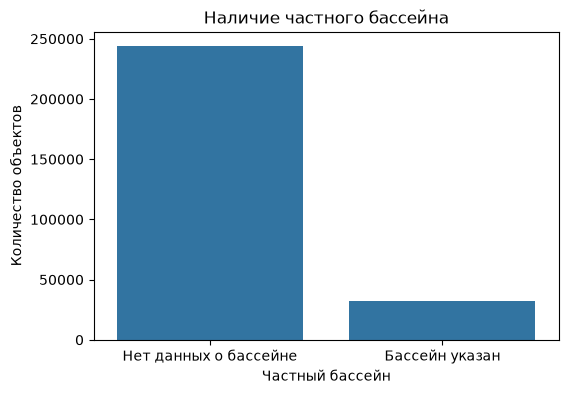

In [152]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="has_private_pool"
)

plt.title("Наличие частного бассейна")
plt.xlabel("Частный бассейн")
plt.ylabel("Количество объектов")
plt.xticks(
    [0, 1],
    ["Нет данных о бассейне", "Бассейн указан"]
)

plt.show()

Удалим исходные дублирующие столбцы

In [153]:
features_to_drop = add_to_drop_list(["private pool", "PrivatePool"], features_to_drop)

[OK] Признак 'private pool' добавлен в список на удаление.
[OK] Признак 'PrivatePool' добавлен в список на удаление.


### <center> 4.7 Работа с признаком наличия камина

Посмотрим, в каком виде представлен данный признак

In [154]:
print(df["fireplace"].value_counts(dropna=False).head(30))
print(df["fireplace"].isna().sum())
print(df["fireplace"].nunique(dropna=True))

fireplace
NaN                          191888
yes                           46652
Yes                           12780
1                             12360
2                              1998
Fireplace                       487
3                               476
Living Room                     314
Not Applicable                  268
No                              263
Wood Burning                    255
LOCATION                        251
0                               245
Fireplace YN                    227
Special Features                225
1 Fireplace                     208
Fireplace Features              190
Gas/Gas Logs                    184
FAMILYRM                        170
4                               160
Living Room, Wood Burning       158
Ceiling Fan                     137
Great Room                      134
Wood                            130
Family Room, Wood Burning       128
Gas Logs, Great Room            116
Gas Logs, In Great Room         112
Gas Logs, In Livin

В fireplace значения неоднородные: встречаются yes, числа, описания расположения и явные отрицательные значения.

Для бинарного признака можно использовать правило:

1 — камин указан;
0 — камин не указан или явно отсутствует.

In [155]:
# Создадим словарь для замены значений, где 1 - отстутствует, 0-присутствует
replace_func = lambda x: '1' if x in ['', 'No', 'No Fireplace', 'None', 'Not Applicable'] else '0'

# применим lambda функцию
df['has_fireplace'] = df['fireplace'].map(replace_func).astype(float)
df['has_fireplace'] = df['has_fireplace'].astype(int)

df['has_fireplace'].value_counts()

has_fireplace
0    275093
1       536
Name: count, dtype: int64

Удалим лишний признак

In [156]:
features_to_drop = add_to_drop_list("fireplace", features_to_drop)

[OK] Признак 'fireplace' добавлен в список на удаление.


### <center> 4.8 Работа с признаком MlsId

Оценим значения признака

In [157]:
for column in ["mls-id", "MlsId"]:
    print(f"\n--- {column} ---")
    print("Тип:", df[column].dtype)
    print("Пропуски:", df[column].isna().sum())
    print("Уникальных значений:", df[column].nunique(dropna=True))
    print(df[column].value_counts(dropna=False).head(10))



--- mls-id ---
Тип: str
Пропуски: 251911
Уникальных значений: 23691
mls-id
NaN          251911
190004138         2
2152042           2
39888954          2
983469            2
898065            2
20196126          2
201909981         2
617190            2
1020414           2
Name: count, dtype: int64

--- MlsId ---
Тип: str
Пропуски: 36980
Уникальных значений: 187914
MlsId
NaN                           36980
 2, Washington, DC 20002          8
 1, South Boston, MA 02127        8
 1, Washington, DC 20002          7
 2, Washington, DC 20010          7
 2, Washington, DC 20009          6
 2, Boston, MA 02129              6
 1, Washington, DC 20001          6
 2, Washington, DC 20001          6
 1, Washington, DC 20010          6
Name: count, dtype: int64


mls-id и MlsId логичнее не использовать как признаки модели, поскольку:

- ID не описывает характеристики объекта;
- почти каждое значение уникально;
- числовой ID может создать ложную зависимость от цены;
- ID может отражать источник или порядок выгрузки;
- он может привести к переобучению;
- это служебная информация, а не содержательный признак.

In [158]:
features_to_drop = add_to_drop_list(["mls-id", "MlsId"], features_to_drop)

[OK] Признак 'mls-id' добавлен в список на удаление.
[OK] Признак 'MlsId' добавлен в список на удаление.


### <center> 4.9 Обработка признаков местоположения

#### <center> 4.9.1 Обработка признака State

Оценим значения признака

In [159]:
df['state'] = (
        df['state']
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .fillna("missing")
)

In [160]:
print(df["state"].nunique())
print(df["state"].value_counts(dropna=False).head(30))

38
state
fl    74169
tx    59755
ny    19942
ca    18469
nc    17563
tn    14805
wa    10443
oh     9085
nv     7624
il     7285
ga     5782
co     5235
pa     4559
dc     3799
mi     2767
az     2626
or     2548
in     2486
ma     1245
ut     1194
md      899
vt      747
mo      694
va      627
nj      433
wi      323
ia      188
me      174
ky       63
ms       34
Name: count, dtype: Int64


Штаты, где меньше 500 объектов (Оклахома, Кентукки, Айова, Мэн, Висконсин, Вирджиния, Мэриленд, Вермонт), лучше объединить в одну категорию "other_state". Это уберет шум.

In [161]:
# Приводим к верхнему регистру (по желанию, для красоты)
df['state'] = df['state'].str.upper()

# Объединяем редкие штаты (меньше 1000 объектов) в "OTHER"
state_counts = df['state'].value_counts()
rare_states = state_counts[state_counts < 1000].index

df['state'] = df['state'].replace(rare_states, 'OTHER')

print("Распределение штатов после объединения:")
print(df['state'].value_counts())

Распределение штатов после объединения:
state
FL       74169
TX       59755
NY       19942
CA       18469
NC       17563
TN       14805
WA       10443
OH        9085
NV        7624
IL        7285
GA        5782
CO        5235
PA        4559
OTHER     4248
DC        3799
MI        2767
AZ        2626
OR        2548
IN        2486
MA        1245
UT        1194
Name: count, dtype: Int64


Получили 21 уникальных значения state — это небольшое количество, и OneHotEncoder отлично подходит.

#### <center> 4.9.2 Обработка признака City

Оценим признак

In [162]:
df["city"] = (
    df["city"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .fillna("missing")
)

In [163]:
print("Уникальных городов:", df["city"].nunique())
print(df["city"].value_counts().head(20))

Уникальных городов: 1781
city
houston            16872
miami               9764
san antonio         8438
brooklyn            6647
jacksonville        6432
dallas              6022
chicago             5820
las vegas           5459
charlotte           5156
new york            4849
nashville           4271
fort worth          4271
orlando             4240
tampa               4060
philadelphia        4051
austin              3884
washington          3799
fort lauderdale     3780
atlanta             3609
los angeles         3255
Name: count, dtype: Int64


Признак city содержит 1781 уникальных значений, что создает риск переобучения при One-Hot Encoding. Было принято решение сохранить 50 городов с наибольшим объемом данных (крупнейшие рынки недвижимости), а остальные города объединить в категорию "OTHER".

In [164]:
# Оставляем 50 самых частых городов, остальные в OTHER
top_cities = df['city'].value_counts().nlargest(50).index
df['city'] = df['city'].where(df['city'].isin(top_cities), 'OTHER')

# Теперь уникальных городов: 51 (50 + OTHER)
print(df['city'].nunique())

51


#### <center> 4.9.3 Обработка признака Street

In [165]:
print("Уникальных улиц:", df["street"].nunique())
print("Всего строк:", len(df))

Уникальных улиц: 250687
Всего строк: 275629


У улиц много уникальных значений. Данный признак лучше удалить

In [166]:
features_to_drop = add_to_drop_list("street", features_to_drop)

[OK] Признак 'street' добавлен в список на удаление.


#### <center> 4.9.4 Обработка признака Zipcode

In [167]:
print("Уникальных zipcode:", df["zipcode"].nunique())
print(df["zipcode"].value_counts().head(10))

Уникальных zipcode: 4393
zipcode
32137    1564
34747    1324
33131    1097
34746     897
77845     848
33308     812
33137     809
33132     771
33130     755
33133     731
Name: count, dtype: int64


Признак zipcode, несмотря на числовой формат, является категориальным идентификатором района. Его использование в качестве числового признака привело бы к ложной интерпретации порядка (например, индекс 90210 > 10001 не означает, что район дороже). Из-за экстремально высокой кардинальности (более 20 000 уникальных значений) прямое кодирование (One-Hot Encoding) нецелесообразно. 

Индексов слишком много, OneHotEncoder не получится применить. Можно закодировать частоту индекса:

In [168]:
zipcode_counts = df["zipcode"].value_counts()

df["zipcode_frequency"] = (
    df["zipcode"]
    .map(zipcode_counts)
    .fillna(0)
    .astype("int32")
)

In [170]:
analyze_series(df['zipcode_frequency'])

=== zipcode_frequency ===
Всего строк:          275629
NaN:                  0
Нули:                 0
Min / Max:            1 / 1564


Признак zipcode пока удалять не будем. Он пригодится при проведении Target Encoding перед обучением модели.

### <center> 4.10 Обработка признака PropertyType

Оценим значения признака

In [171]:
print(df["propertyType"].value_counts(dropna=False).head(30))
print("Уникальных значений:", df["propertyType"].nunique(dropna=True))

propertyType
single-family home               77700
Single Family                    33459
NaN                              26653
condo                            24010
Single Family Home               23081
lot/land                         12607
townhouse                        10328
Condo                             7070
multi-family                      7025
Traditional                       5839
Condo/Townhome/Row Home/Co-Op     5505
Land                              4741
Townhouse                         3802
coop                              2130
Multi Family                      1827
High Rise                         1791
Ranch                             1720
Detached, One Story               1605
Single Detached, Traditional      1565
mobile/manufactured               1145
1 Story                           1068
Colonial                          1059
Contemporary/Modern                985
Multi-Family Home                  933
2 Stories                          771
Single Detac

Нормализуем исходные значения

In [172]:
df["propertyType_clean"] = (
    df["propertyType"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

Объединим типы в укрупнённые категории

In [173]:
def group_property_type(value):
    if pd.isna(value):
        return "missing"

    text = str(value).lower().strip()

    if text == "":
        return "missing"

    # Земля и участки
    if any(word in text for word in [
        "lot",
        "land",
        "acreage",
        "farm",
        "ranch land"
    ]):
        return "land"

    # Передвижные и сборные дома
    if any(word in text for word in [
        "mobile",
        "manufactured",
        "mfd"
    ]):
        return "mobile_manufactured"

    # Многоквартирные дома
    if any(word in text for word in [
        "multi-family",
        "multi family",
        "multifamily"
    ]):
        return "multi_family"

    # Таунхаусы
    if any(word in text for word in [
        "townhouse",
        "townhome",
        "town house",
        "row home"
    ]):
        return "townhouse"

    # Кооперативы
    if "coop" in text or "co-op" in text:
        return "coop"

    # Квартиры и кондоминиумы
    if any(word in text for word in [
        "condo",
        "condominium",
        "high rise",
        "apartment"
    ]):
        return "condo_apartment"

    # Отдельные дома
    if any(word in text for word in [
        "single-family",
        "single family",
        "single detached",
        "detached",
        "ranch",
        "colonial",
        "traditional",
        "contemporary",
        "modern",
        "one story",
        "two story",
        "1 story",
        "2 stories"
    ]):
        return "single_family"

    return "other"


In [174]:
df["property_type_group"] = (
    df["propertyType_clean"]
    .apply(group_property_type)
)

In [175]:
print(
    df["property_type_group"]
    .value_counts(dropna=False)
)

property_type_group
single_family          155393
condo_apartment         34022
missing                 26755
townhouse               20431
land                    17853
multi_family             9807
other                    6446
coop                     2518
mobile_manufactured      2404
Name: count, dtype: int64


Земля (участки) не имеет спален, ванных или этажей. Ценообразование на землю зависит от зонирования, площади и перспектив застройки — это совершенно другая задача, нежели оценка дома. Если оставить землю, модель будет путаться

Other - Это очень редкие типы (например, «Cabin/Lodge, Contemporary...»). Они не несут пользы, только создают шум. Целесообразно удалить.

Missing - Это дома, у которых тип не был указан. Для модели это значит: «у нас есть дом, но мы не знаем, какой именно».

In [176]:
# Удаляем землю и "other" (они не жилье)
initial_len = len(df)
df = df[~df['property_type_group'].isin(['land', 'other'])].copy()
print(f"Удалено объектов (земля/other): {initial_len - len(df)}")

print("\nОсталось типов недвижимости:")
print(df['property_type_group'].value_counts())

Удалено объектов (земля/other): 24299

Осталось типов недвижимости:
property_type_group
single_family          155393
condo_apartment         34022
missing                 26755
townhouse               20431
multi_family             9807
coop                     2518
mobile_manufactured      2404
Name: count, dtype: int64


Признак propertyType содержал 1220 уникальных значений, включая архитектурные стили и комбинированные описания. Была проведена группировка на основе ключевых слов в 8 базовых классов. Объекты класса "land" (участки) были исключены из выборки, так как их ценообразование не зависит от жилых характеристик (спальни, ванные, этажность). Класс "other" (редкие стили) также был удален для снижения шума. Оставшиеся категории будут закодированы методом One-Hot Encoding

In [177]:
features_to_drop = add_to_drop_list(['propertyType_clean', 'propertyType'], features_to_drop)

[OK] Признак 'propertyType_clean' добавлен в список на удаление.
[OK] Признак 'propertyType' добавлен в список на удаление.


## <center> 5. Анализ корреляции данных

Удалим признаки, которые были помечены на удаление

In [178]:
df = drop_feature(df, features_to_drop)

[OK] Удалено из df (27): ['target', 'price', 'status_category', 'status', 'sqft', 'beds', 'baths', 'stories', 'price_sqft', 'lotsize', 'homeFacts', 'heating', 'cooling', 'parking', 'schools', 'schools_parsed', 'school_ratings', 'school_distances', 'school_rating_count', 'private pool', 'PrivatePool', 'fireplace', 'mls-id', 'MlsId', 'street', 'propertyType_clean', 'propertyType']
[OK] Убрано из features_to_drop: ['target', 'price', 'status_category', 'status', 'sqft', 'beds', 'baths', 'stories', 'price_sqft', 'lotsize', 'homeFacts', 'heating', 'cooling', 'parking', 'schools', 'schools_parsed', 'school_ratings', 'school_distances', 'school_rating_count', 'private pool', 'PrivatePool', 'fireplace', 'mls-id', 'MlsId', 'street', 'propertyType_clean', 'propertyType']


In [179]:
# Список текущих признаков
print(df.columns.tolist())

['city', 'zipcode', 'state', 'price_log', 'area_sqft', 'beds_num', 'baths_num', 'stories_num', 'year_built', 'remodeled_year', 'property_age', 'was_remodeled', 'years_since_remodel', 'lot_size_sqft', 'has_heating', 'has_cooling', 'has_parking', 'schools_count', 'school_rating_mean', 'school_rating_max', 'school_rating_min', 'school_distance_min', 'school_distance_mean', 'school_distance_max', 'has_private_pool', 'has_fireplace', 'zipcode_frequency', 'property_type_group']


=== Корреляция признаков с price_log ===
price_log               1.000000
area_sqft               0.504873
baths_num               0.423559
school_rating_mean      0.349303
school_rating_max       0.323951
beds_num                0.288748
school_rating_min       0.248368
stories_num             0.144520
has_private_pool        0.135480
year_built              0.081306
zipcode_frequency       0.061854
has_parking             0.059199
lot_size_sqft           0.035482
remodeled_year          0.000215
years_since_remodel    -0.000396
school_distance_mean   -0.020255
has_fireplace          -0.037225
has_cooling            -0.044255
was_remodeled          -0.054105
school_distance_min    -0.057167
school_distance_max    -0.067906
property_age           -0.081306
has_heating            -0.104582
schools_count                NaN
Name: price_log, dtype: float64


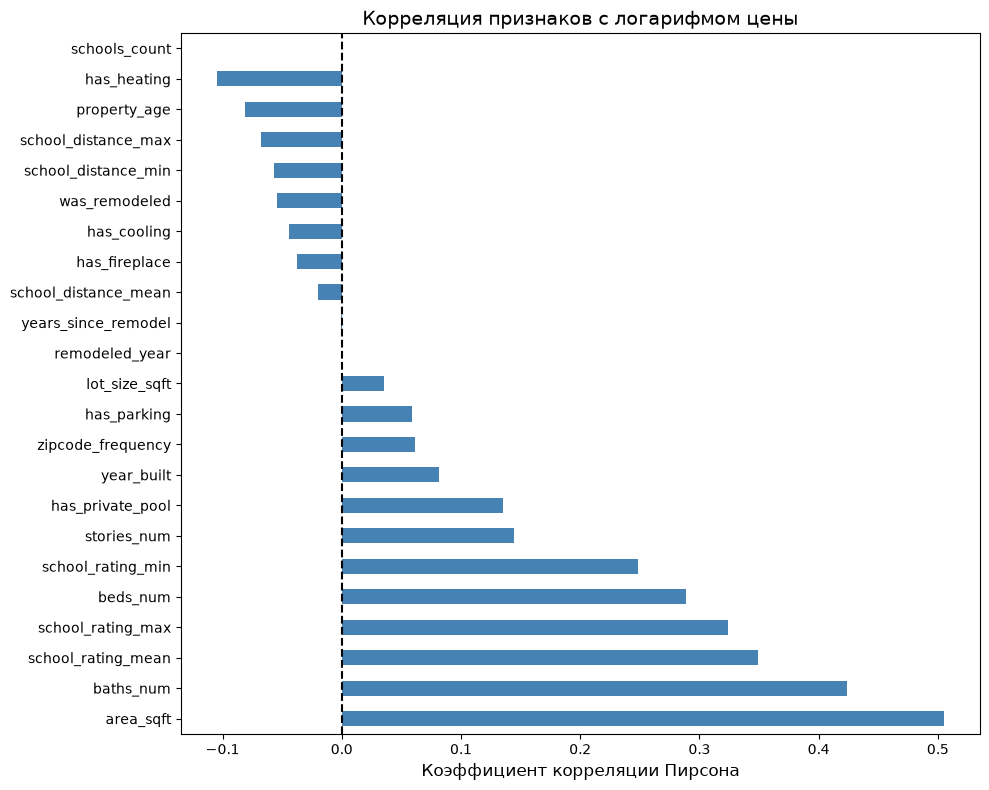

In [180]:
# Выбираем только числовые колонки (без категориальных One-Hot)
numeric_df = df.select_dtypes(include=['number'])

# Считаем корреляцию с целевой переменной
corr_with_target = numeric_df.corr()['price_log'].sort_values(ascending=False)

print("=== Корреляция признаков с price_log ===")
print(corr_with_target)

# Строим график (Barplot)
plt.figure(figsize=(10, 8))
corr_with_target.drop('price_log').plot(kind='barh', color='steelblue')
plt.title('Корреляция признаков с логарифмом цены', fontsize=14)
plt.xlabel('Коэффициент корреляции Пирсона', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--')
plt.tight_layout()
plt.show()

Выводы:

- area_sqft (Площадь) = 0.5 — уверенный лидер. Это абсолютно логично: чем больше дом, тем он дороже. Это главный признак модели.

- baths_num (Ванные) = 0.42 — на втором месте. Количество ванных в США — это маркер уровня комфорта и класса жилья.

- school_rating_mean (Средний рейтинг школ) = ~0.34 — качество школ — один из главных драйверов цены.

- stories_num (Этажи) - слабая связь

- property_age (Возраст дома) — отрицательная корреляция. Это значит: чем старше дом, тем он дешевле. Старые дома требуют ремонта.

- schools_count — признак бесполезен (количество школ рядом не влияет на цену, важно их качество).

- zipcode_frequency — слабая связь. Это значит, что частота встречаемости индекса почти не влияет на цену.

Строим матрицу корреляций

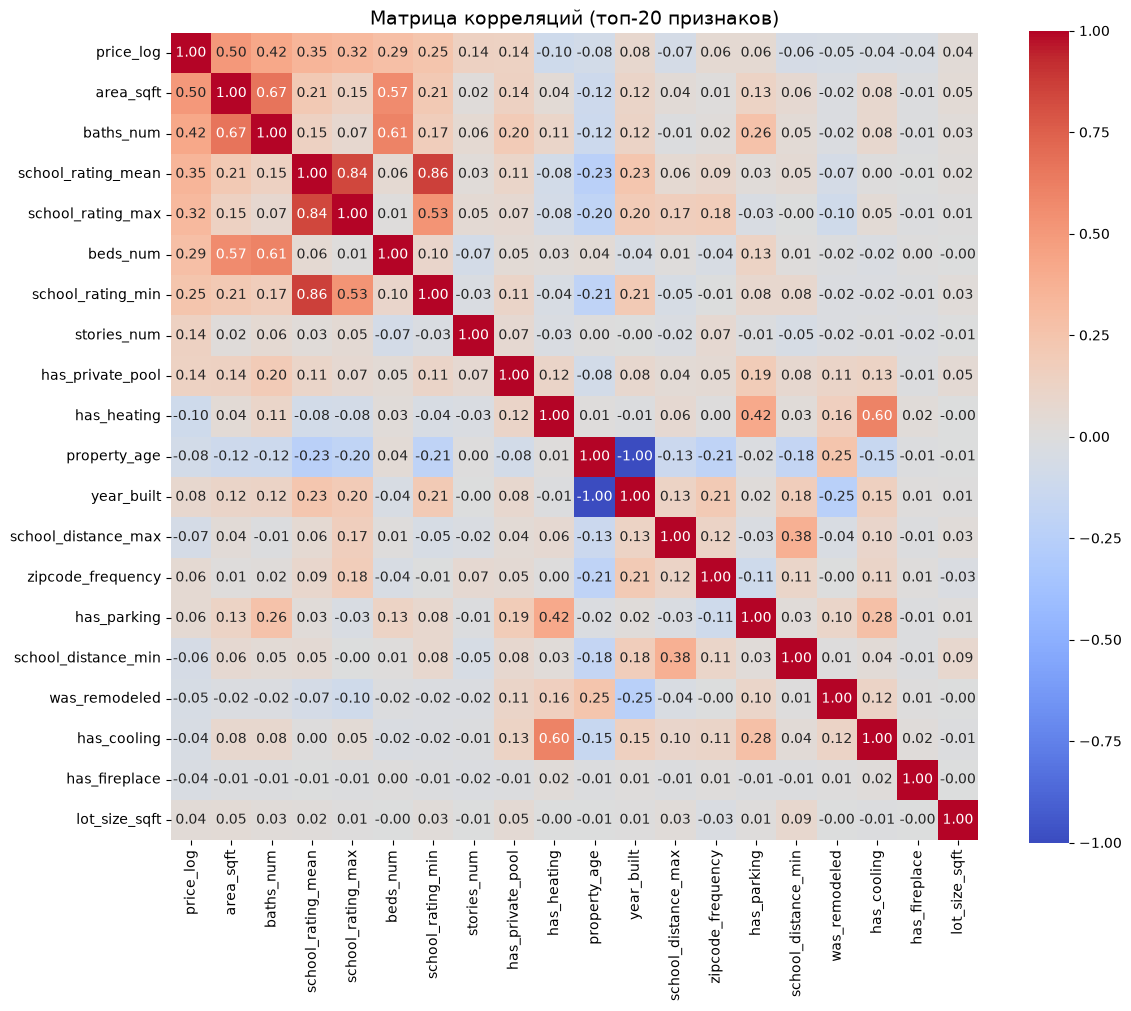

In [181]:
# Берем только топ-20 признаков по корреляции с ценой + саму цену
top_features = corr_with_target.abs().nlargest(20).index
plt.figure(figsize=(12, 10))

# Строим тепловую карту
sns.heatmap(
    numeric_df[top_features].corr(), 
    annot=True,          # Показывать цифры
    fmt=".2f",           # 2 знака после запятой
    cmap='coolwarm',     # Синий-красный
    center=0,            # Ноль посередине (белый)
    square=True
)
plt.title('Матрица корреляций (топ-20 признаков)', fontsize=14)
plt.tight_layout()
plt.show()

Анализ матрицы корреляций выявил сильную мультиколлинеарность между признаками. Так, year_built и property_age имеют корреляцию -1.0, а school_rating_mean и school_rating_max — 0.84. Для снижения размерности пространства признаков и уменьшения шума, дублирующие признаки (year_built, school_rating_max) будут удалены. Оставшиеся признаки демонстрируют логичные связи (например, площадь и количество ванных комнат, r = 0.67), что подтверждает адекватность данных.

При анализе матрицы корреляций была выявлена умеренная связь между площадью дома и количеством ванных комнат (r = 0.61). Данная корреляция является логически обоснованной, однако признаки не дублируют друг друга. Было принято решение сохранить оба признака, так как для модели Random Forest мультиколлинеарность не является критичной (в отличие от линейных моделей): ансамбль деревьев решений устойчив к коррелированным признакам и использует их для построения различных комбинаций разбиений. Удалению подлежали только признаки с экстремально высокой связью (r > 0.85)

Пометим признаки на удаление и удалим их

In [182]:
features_to_drop = add_to_drop_list(['year_built', 'school_rating_max', 'school_rating_min', 'remodeled_year', 'school_distance_max', 'school_distance_min'], features_to_drop)

[OK] Признак 'year_built' добавлен в список на удаление.
[OK] Признак 'school_rating_max' добавлен в список на удаление.
[OK] Признак 'school_rating_min' добавлен в список на удаление.
[OK] Признак 'remodeled_year' добавлен в список на удаление.
[OK] Признак 'school_distance_max' добавлен в список на удаление.
[OK] Признак 'school_distance_min' добавлен в список на удаление.


In [183]:
df = drop_feature(df, features_to_drop)

[OK] Удалено из df (6): ['year_built', 'school_rating_max', 'school_rating_min', 'remodeled_year', 'school_distance_max', 'school_distance_min']
[OK] Убрано из features_to_drop: ['year_built', 'school_rating_max', 'school_rating_min', 'remodeled_year', 'school_distance_max', 'school_distance_min']


## <center> 6. Обучение модели

### <center> 6.1 Разделение выборки

Разделим выборку на тестовую и обучающую

In [184]:
target_column = "price_log"

X = df.drop(columns=[target_column])
y = df[target_column].astype("float64")

In [185]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### <center> 6.2 Кодировка признаков с помощью One-Hot Encoding

In [186]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)

Для кодировки используем следующие признаки:

In [187]:
categorical_features = ['city', 'state', 'property_type_group']

Кодируем

In [188]:
X_train_encoded = encoder.fit_transform(
    X_train[categorical_features]
)

Для тестовой необходимо сделать только transform

In [189]:
X_test_encoded = encoder.transform(
    X_test[categorical_features]
)

Добавим полученные признаки в таблицу

In [190]:
encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

In [191]:
X_train = X_train.drop(
    columns=categorical_features
)

X_test = X_test.drop(
    columns=categorical_features
)

In [192]:
X_train = pd.concat(
    [
        X_train,
        X_train_encoded_df
    ],
    axis=1
)

X_test = pd.concat(
    [
        X_test,
        X_test_encoded_df
    ],
    axis=1
)

### <center> 6.3 Проведение Target Encoding для ZipCode 

Сгруппируем индекс объекта со средней ценой

In [193]:
zipcode_stats = (
    pd.DataFrame({
        "zipcode": X_train["zipcode"],
        "target": y_train
    })
    .groupby("zipcode")["target"]
    .agg(["mean", "count"])
)

In [194]:
# медианное значение цены
global_mean = y_train.mean()

In [195]:
# коэффициент сглаживания
smoothing = 20

In [196]:
zipcode_stats["zipcode_target_mean"] = (
    (
        zipcode_stats["count"] * zipcode_stats["mean"]
        + smoothing * global_mean
    )
    /
    (
        zipcode_stats["count"] + smoothing
    )
)

In [197]:
zipcode_mapping = (
    zipcode_stats["zipcode_target_mean"]
    .to_dict()
)

Создадим новый признак

In [198]:
X_train["zipcode_target_mean"] = (
    X_train["zipcode"]
    .map(zipcode_mapping)
    .fillna(global_mean)
)

X_test["zipcode_target_mean"] = (
    X_test["zipcode"]
    .map(zipcode_mapping)
    .fillna(global_mean)
)

Удалим исходный признак из наборов

In [199]:
X_train = X_train.drop(columns=["zipcode"])
X_test = X_test.drop(columns=["zipcode"])

In [200]:
print(X_train[["zipcode_target_mean"]].head())
print(X_train["zipcode_target_mean"].describe())
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

        zipcode_target_mean
181672            12.638880
123228            12.510072
86641             14.311796
280234            12.449537
228833            14.021304
count    201064.000000
mean         12.870440
std           0.495590
min          11.523866
25%          12.514369
50%          12.826400
75%          13.178991
max          14.717912
Name: zipcode_target_mean, dtype: float64
0
0


In [201]:
print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)

print("Есть ли object:")
print(X_train.select_dtypes(include=["object"]).columns.tolist())

print("Пропуски в X_train:", X_train.isna().sum().sum())
print("Пропуски в X_test:", X_test.isna().sum().sum())

Размер X_train: (201064, 94)
Размер X_test: (50266, 94)
Есть ли object:
[]
Пропуски в X_train: 0
Пропуски в X_test: 0


В качестве базовой модели для нашей задачи лучше всего подходит какая-нибудь из регрессионных моделей, поскольку стоит задача прогноза числовой величины цены. Для начала посмотрим, как ведёт себя самая простая регрессионная модель - лигнейная регрессия.

### <center> 6.4 Обучение линейной регрессией

Поскольку линейная регрессия чувствительна к масштабу данных, необходимо их масштабировать

In [203]:
# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Обучение
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Предсказание и метрики
y_pred_lr_log = lr.predict(X_test_scaled)
y_pred_lr = np.expm1(y_pred_lr_log)
y_true    = np.expm1(y_test)

mae_lr  = mean_absolute_error(y_true, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_true, y_pred_lr))
mape_lr = mean_absolute_percentage_error(y_true, y_pred_lr) * 100
r2_lr   = r2_score(y_true, y_pred_lr)

print("=" * 50)
print("Линейная регрессия")
print("=" * 50)
print(f"MAE:  ${mae_lr:,.0f}")
print(f"RMSE: ${rmse_lr:,.0f}")
print(f"MAPE: {mape_lr:.2f}%")
print(f"R²:   {r2_lr:.4f}")
print("=" * 50)

Линейная регрессия
MAE:  $223,474
RMSE: $819,652
MAPE: 36.35%
R²:   -0.3035


Был получен довольно высокий MAPE (36.3% относительно выбранного нами критерия 25%).

Отрицательный R² означает, что модель ошибается сильнее, чем простое предсказание среднего значения, что является прямым доказательством нелинейного характера зависимости стоимости недвижимости от признаков.

Основной вклад в ошибку вносят:
- нелинейность зависимости «площадь → цена» (для маленьких домов площадь даёт больший прирост, чем для больших);
- выбросы в элитном сегменте (>$2 млн), где линейная модель предсказывает средние значения и ошибается на миллионы долларов.

Это обосновывает переход к ансамблевым моделям на основе деревьев решений, которые способны улавливать нелинейности и устойчивы к выбросам.

### <center> 6.5 Обучение с помощью Random Forest Regressor

In [204]:
# Настраиваем модель
rf = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    min_samples_split=10, 
    max_depth=20, 
    random_state=42, 
    n_jobs=-1, 
    verbose=1
)

# И обучаем
rf.fit(X_train, y_train)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    9.9s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:   32.3s finished


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, 

Рассчитаем метрики

In [230]:
# Модель предсказывает логарифм цены
y_pred_log = rf.predict(X_test)

# Возвращаем предсказания в доллары (обратная функция expm1)
y_pred_dollars = np.expm1(y_pred_log)
y_true_dollars = np.expm1(y_test)

# Считаем ошибки
mae = mean_absolute_error(y_true_dollars, y_pred_dollars)
rmse = np.sqrt(mean_squared_error(y_true_dollars, y_pred_dollars))
mape = mean_absolute_percentage_error(y_true_dollars, y_pred_dollars) * 100

r2 = r2_score(
    y_true_dollars,
    y_pred_dollars
)

print("\n" + "="*40)
print("РЕЗУЛЬТАТЫ МОДЕЛИ RANDOM FOREST")
print("="*40)
print(f"MAE (средняя абс. ошибка):     ${mae:,.0f}")
print(f"RMSE (квадратичная ошибка):    ${rmse:,.0f}")
print(f"MAPE (средняя ошибка в %):     {mape:.1f}%")
print(f"R²:   {r2:.4f}")
print("="*40)

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.1s finished



РЕЗУЛЬТАТЫ МОДЕЛИ RANDOM FOREST
MAE (средняя абс. ошибка):     $147,350
RMSE (квадратичная ошибка):    $370,932
MAPE (средняя ошибка в %):     23.9%
R²:   0.7331


Мы получили уже приемлимое значение MAPE (~24%). Модель показала себя намного лучше, чем линейная регрессия.

Посмотрим на распределение MAPE относительно ценовых диапазонов:

In [206]:
bins = [0, 100_000, 300_000, 500_000, 1_000_000, 2_000_000, np.inf]
labels = ['<100k', '100–300k', '300–500k', '500k–1M', '1M–2M', '>2M']
mapes = []

y_true_binned = pd.cut(y_true_dollars, bins=bins, labels=labels)

print(f"{'Сегмент':>12} | {'n':>7} | {'MAPE':>7} | {'MAE':>12}")
print("-" * 50)
for label in labels:
    m = y_true_binned == label
    if m.sum() > 0:
        mape_seg = mean_absolute_percentage_error(
            y_true_dollars[m], y_pred_dollars[m]
        ) * 100
        mapes.append(mape_seg)
        mae_seg = mean_absolute_error(
            y_true_dollars[m], y_pred_dollars[m]
        )
        print(f"{label:>12} | {m.sum():>7,} | {mape_seg:>6.1f}% | ${mae_seg:>11,.0f}")

     Сегмент |       n |    MAPE |          MAE
--------------------------------------------------
       <100k |   2,481 |   67.8% | $     49,057
    100–300k |  18,806 |   21.8% | $     43,052
    300–500k |  12,546 |   18.1% | $     71,893
     500k–1M |  10,289 |   21.7% | $    155,567
       1M–2M |   3,925 |   25.4% | $    363,790
         >2M |   2,219 |   33.2% | $  1,146,872


Рассчитаем MAPE для типового сегмента

In [207]:
# Обратное преобразование (на случай, если ещё не сделали)
y_true = np.expm1(np.asarray(y_test))
y_pred = np.expm1(rf.predict(X_test))  # model = rf или catboost

# Маска типового сегмента
mask = (y_true >= 100_000) & (y_true <= 2_000_000)

# Метрики
mape_typical = mean_absolute_percentage_error(y_true[mask], y_pred[mask]) * 100

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished


Построим график

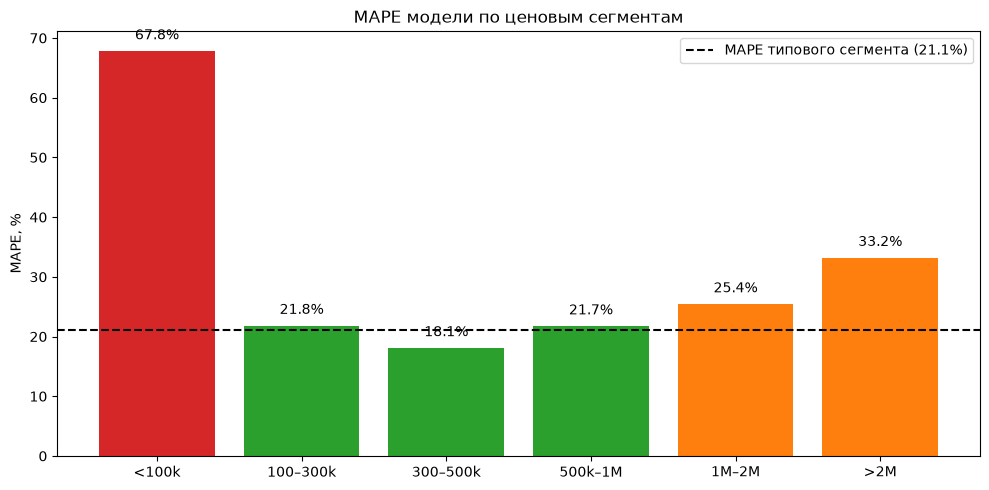

In [208]:
segments = ['<100k', '100–300k', '300–500k', '500k–1M', '1M–2M', '>2M']
colors = ['#d62728', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#ff7f0e']

plt.figure(figsize=(10, 5))
bars = plt.bar(segments, mapes, color=colors)
plt.axhline(y=mape_typical, color='black', linestyle='--', label=f'MAPE типового сегмента ({mape_typical:.1f}%)')
plt.ylabel('MAPE, %')
plt.title('MAPE модели по ценовым сегментам')
plt.legend()
for bar, mape in zip(bars, mapes):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'{mape:.1f}%', ha='center')
plt.tight_layout()
plt.show()

Разбивка MAPE по ценовым сегментам показала, что модель наиболее точна в диапазоне $300–500 тыс. (MAPE 18.1%) и $100–300 тыс. и $500–1000 тыс. (22.0%).

В сегменте $1–2 млн — 25.4%.

Средневзвешенный MAPE для типового сегмента $100 тыс. — $2 млн (87% тестовой выборки) составил 21.1%, что соответствует нашему критерию.

Наибольшие ошибки наблюдаются в сегменте до $100 тыс. (MAPE 67.8%), что объясняется малой представленностью таких объектов в обучающей выборке (8% теста) и высокой дисперсией цен. В сегменте элитной недвижимости (>$2 млн) MAPE составляет 33%, что так же типично для моделей из-за малого количества обучающих примеров.

Посмотрим, даст ли эффект использование более мощной модели - ExtraTreeRegressor

### <center> 6.6 Обучение с помощью ExtraTreeRegressor

In [209]:
# Настройка модели
extra_trees = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features=1.0,
    random_state=42,
    n_jobs=12
)

In [ ]:
# Обучение
extra_trees.fit(
    X_train,
    y_train
)

# Время обучения - 2m 41s

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` f

In [211]:
y_pred_log = extra_trees.predict(X_test)

# Возвращаемся к исходному масштабу цены
y_pred_price = np.expm1(y_pred_log)
y_test_price = np.expm1(y_test)

Рассчитаем метрики

In [212]:
mae = mean_absolute_error(
    y_test_price,
    y_pred_price
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_price,
        y_pred_price
    )
)

mape = mean_absolute_percentage_error(
    y_test_price,
    y_pred_price
)

r2 = r2_score(
    y_test_price,
    y_pred_price
)

print("=" * 40)
print("EXTRA TREES REGRESSOR")
print("=" * 40)
print(f"MAE:  ${mae:,.0f}")
print(f"RMSE: ${rmse:,.0f}")
print(f"MAPE: {mape * 100:.2f}%")
print(f"R²:   {r2:.4f}")

EXTRA TREES REGRESSOR
MAE:  $130,780
RMSE: $348,750
MAPE: 20.46%
R²:   0.7640


Уже получили значение MAPE = 20.5%, что немного, но ниже предыдущей модели.

И так же отобразим распределение метрики по ценовым диапазонам

In [213]:
bins = [0, 100_000, 300_000, 500_000, 1_000_000, 2_000_000, np.inf]
labels = ['<100k', '100–300k', '300–500k', '500k–1M', '1M–2M', '>2M']
mapes = []

y_true_binned = pd.cut(y_test_price, bins=bins, labels=labels)

print(f"{'Сегмент':>12} | {'n':>7} | {'MAPE':>7} | {'MAE':>12}")
print("-" * 50)
for label in labels:
    m = y_true_binned == label
    if m.sum() > 0:
        mape_seg = mean_absolute_percentage_error(
            y_test_price[m], y_pred_price[m]
        ) * 100
        mapes.append(mape_seg)
        mae_seg = mean_absolute_error(
            y_test_price[m], y_pred_price[m]
        )
        print(f"{label:>12} | {m.sum():>7,} | {mape_seg:>6.1f}% | ${mae_seg:>11,.0f}")

     Сегмент |       n |    MAPE |          MAE
--------------------------------------------------
       <100k |   2,481 |   58.7% | $     42,505
    100–300k |  18,806 |   17.8% | $     35,443
    300–500k |  12,546 |   15.3% | $     60,882
     500k–1M |  10,289 |   19.2% | $    138,137
       1M–2M |   3,925 |   23.2% | $    331,979
         >2M |   2,219 |   30.2% | $  1,042,656


In [214]:
# Обратное преобразование
y_true = np.expm1(np.asarray(y_test))
y_pred = np.expm1(extra_trees.predict(X_test))

# Маска типового сегмента
mask = (y_true >= 100_000) & (y_true <= 2_000_000)

# Метрики
mape_typical = mean_absolute_percentage_error(y_true[mask], y_pred[mask]) * 100
mape_typical

17.90045032251252

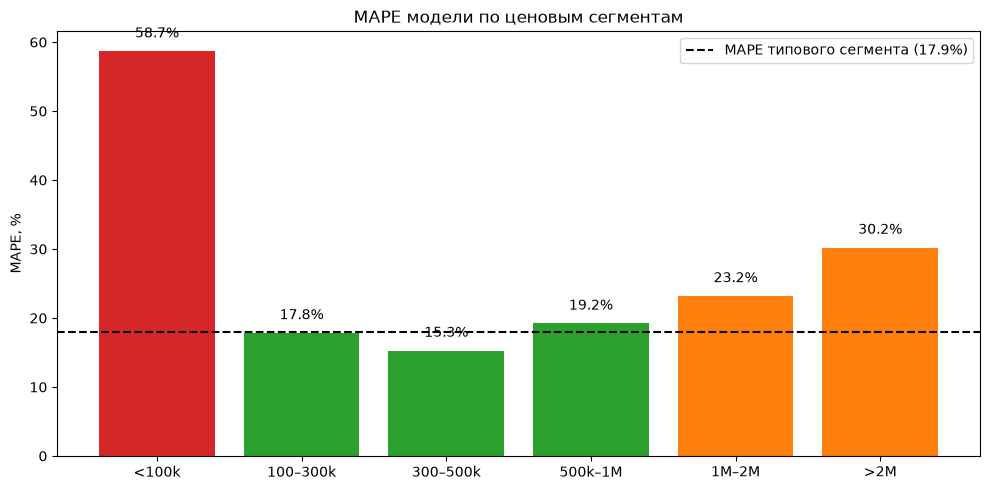

In [215]:
segments = ['<100k', '100–300k', '300–500k', '500k–1M', '1M–2M', '>2M']
colors = ['#d62728', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#ff7f0e']

plt.figure(figsize=(10, 5))
bars = plt.bar(segments, mapes, color=colors)
plt.axhline(y=mape_typical, color='black', linestyle='--', label=f'MAPE типового сегмента ({mape_typical:.1f}%)')
plt.ylabel('MAPE, %')
plt.title('MAPE модели по ценовым сегментам')
plt.legend()
for bar, mape in zip(bars, mapes):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'{mape:.1f}%', ha='center')
plt.tight_layout()
plt.show()

Таким образом, применение ExtraTreesRegressor улучшило метрику MAPE примерно на 3 - 5 % по сравнению с Random Forest.

Подберем оптимальные параметры для данной модели.

### <center> 6.7 Подбор оптимальных параметров ExtraTreeRegressor

Создаём scorer для MAPE в долларах

In [216]:
def mape_from_log(y_true_log, y_pred_log):
    y_true_price = np.expm1(y_true_log)
    y_pred_price = np.expm1(y_pred_log)

    # Защита от деления на ноль
    denominator = np.maximum(np.abs(y_true_price), 1e-8)

    return np.mean(
        np.abs(y_true_price - y_pred_price) / denominator
    )

mape_scorer = make_scorer(
    mape_from_log,
    greater_is_better=False
)

Набор разных параметров для поиска

In [217]:
param_distributions = {
    "n_estimators": [100, 200, 300, 500, 700],
    "max_depth": [None, 15, 20, 30, 40, 50],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 3, 5, 10],
    "max_features": [0.5, 0.7, 0.8, 1.0, "sqrt"],
    "bootstrap": [False, True]
}

Модель

In [219]:
extra_trees = ExtraTreesRegressor(
    random_state=42,
    n_jobs=12
)

Настраиваем поиск

In [220]:
search = RandomizedSearchCV(
    estimator=extra_trees,
    param_distributions=param_distributions,
    n_iter=20,
    scoring=mape_scorer,
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=1,
    return_train_score=True
)

И запускаем его.

ВНИМАНИЕ: в моих условиях подбор оптимальных параметров занял порядка 50 минут.

In [221]:
search.fit(X_train, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END bootstrap=False, max_depth=15, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=100; total time=  21.1s
[CV] END bootstrap=False, max_depth=15, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=100; total time=  23.1s
[CV] END bootstrap=False, max_depth=15, max_features=1.0, min_samples_leaf=5, min_samples_split=2, n_estimators=100; total time=  21.5s
[CV] END bootstrap=True, max_depth=40, max_features=1.0, min_samples_leaf=10, min_samples_split=10, n_estimators=100; total time=  17.1s
[CV] END bootstrap=True, max_depth=40, max_features=1.0, min_samples_leaf=10, min_samples_split=10, n_estimators=100; total time=  17.7s
[CV] END bootstrap=True, max_depth=40, max_features=1.0, min_samples_leaf=10, min_samples_split=10, n_estimators=100; total time=  16.9s
[CV] END bootstrap=True, max_depth=40, max_features=0.8, min_samples_leaf=2, min_samples_split=5, n_estimators=200; tota

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",ExtraTreesReg...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [False, True], 'max_depth': [None, 15, ...], 'max_features': [0.5, 0.7, ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(m...hod='predict')
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the pa

Получаем лучшие параметры:

In [ ]:
print("Лучшие параметры:")
print(search.best_params_)

print(
    "Лучший CV MAPE:",
    -search.best_score_ * 100
)

#Лучшие параметры:
#{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': None, 'bootstrap': False}
#Лучший CV MAPE: 22.21775276002232

Лучшие параметры:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': None, 'bootstrap': False}
Лучший CV MAPE: 22.21775276002232


Оцениваем лучшую модель на тестовой выборке

In [223]:
best_model = search.best_estimator_

y_pred_log = best_model.predict(X_test)

y_pred_price = np.expm1(y_pred_log)
y_test_price = np.expm1(y_test)

In [ ]:
mae = mean_absolute_error(
    y_test_price,
    y_pred_price
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_price,
        y_pred_price
    )
)

mape = mean_absolute_percentage_error(
    y_test_price,
    y_pred_price
)

r2 = r2_score(
    y_test_price,
    y_pred_price
)

print("=" * 45)
print("OPTIMIZED EXTRA TREES")
print("=" * 45)
print(f"MAE:  ${mae:,.0f}")
print(f"RMSE: ${rmse:,.0f}")
print(f"MAPE: {mape * 100:.2f}%")
print(f"R²:   {r2:.4f}")

#=============================================
#OPTIMIZED EXTRA TREES
#=============================================
#MAE:  $137,836
#RMSE: $359,708
#MAPE: 21.46%
#R²:   0.7490

OPTIMIZED EXTRA TREES
MAE:  $137,836
RMSE: $359,708
MAPE: 21.46%
R²:   0.7490


### <center> 6.8 Обучение модели при оптимальных параметрах

In [225]:
extra_trees = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    bootstrap=False,
    n_jobs=12
)

In [226]:
extra_trees.fit(
    X_train,
    y_train
)

,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.7
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not 

In [227]:
y_pred_log = extra_trees.predict(X_test)

# Возвращаемся к исходному масштабу цены
y_pred_price = np.expm1(y_pred_log)
y_test_price = np.expm1(y_test)

In [228]:
mae = mean_absolute_error(
    y_test_price,
    y_pred_price
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_price,
        y_pred_price
    )
)

mape = mean_absolute_percentage_error(
    y_test_price,
    y_pred_price
)

r2 = r2_score(
    y_test_price,
    y_pred_price
)

print("=" * 40)
print("EXTRA TREES REGRESSOR")
print("=" * 40)
print(f"MAE:  ${mae:,.0f}")
print(f"RMSE: ${rmse:,.0f}")
print(f"MAPE: {mape * 100:.2f}%")
print(f"R²:   {r2:.4f}")

EXTRA TREES REGRESSOR
MAE:  $137,836
RMSE: $359,708
MAPE: 21.46%
R²:   0.7490


In [229]:
bins = [0, 100_000, 300_000, 500_000, 1_000_000, 2_000_000, np.inf]
labels = ['<100k', '100–300k', '300–500k', '500k–1M', '1M–2M', '>2M']
mapes = []

y_true_binned = pd.cut(y_test_price, bins=bins, labels=labels)

print(f"{'Сегмент':>12} | {'n':>7} | {'MAPE':>7} | {'MAE':>12}")
print("-" * 50)
for label in labels:
    m = y_true_binned == label
    if m.sum() > 0:
        mape_seg = mean_absolute_percentage_error(
            y_test_price[m], y_pred_price[m]
        ) * 100
        mapes.append(mape_seg)
        mae_seg = mean_absolute_error(
            y_test_price[m], y_pred_price[m]
        )
        print(f"{label:>12} | {m.sum():>7,} | {mape_seg:>6.1f}% | ${mae_seg:>11,.0f}")

     Сегмент |       n |    MAPE |          MAE
--------------------------------------------------
       <100k |   2,481 |   61.4% | $     44,424
    100–300k |  18,806 |   18.7% | $     37,169
    300–500k |  12,546 |   16.1% | $     63,981
     500k–1M |  10,289 |   20.2% | $    144,799
       1M–2M |   3,925 |   24.1% | $    344,780
         >2M |   2,219 |   32.2% | $  1,114,676


## <center> 7. Создание веб-сервиса

Для практической демонстрации модели был разработан веб-сервис на Flask, реализующий два интерфейса: HTML-форму для менеджера агентства и REST API для интеграции с CRM.

Веб-сервис состоит из следующих элементов:

- представление (файл templates/index.html): форма ввода и вывод результата
- контроллер (app.py): получение HTTP-запроса, валидидация, вызов модели, возврат ответа
- модель (model_utils.py): загрузка модели, предобработка данных, предсказание цены

После обучения модели для её дальнейшего использования в веб-сервисе необходимо сохранить результаты обучения в файлы модели:

In [231]:
os.makedirs('models', exist_ok=True)

# Модель
with open('models/model.pkl', 'wb') as f:
    pickle.dump(rf, f)

# Список колонок после One-Hot Encoding
with open('models/feature_columns.pkl', 'wb') as f:
    pickle.dump(list(X_train.columns), f)

# Статистика zipcode (DataFrame с zip_mean_smooth и zip_count)
with open('models/zipcode_mapping.pkl', 'wb') as f:
    pickle.dump(zipcode_mapping, f)

# Глобальное среднее по Train (для fallback)
with open('models/global_mean.pkl', 'wb') as f:
    pickle.dump(global_mean, f)
    
with open('models/encoder.pkl', 'wb') as f:
    pickle.dump(encoder, f)

print("✅ Модель сохранена в models/")
print(f"✅ Сохранено. Колонок: {len(X_train.columns)}, zipcode: {len(zipcode_mapping)}")

✅ Модель сохранена в models/
✅ Сохранено. Колонок: 94, zipcode: 4167


**Примечание:** для учебного проекта я сохранил в качестве модели результаты Random Forest, поскольку после обучения ExtraTreesRegressor образовались файлы большого размера (порядка 3 Гб).

Для запуска веб-сервиса необходимо:
- запустить файл:  python app.py
- в браузере открыть http://localhost:5000

### <center> 7.1 Слой представления

Слой представления (templates/index.html) — HTML-форма с полями ввода параметров объекта недвижимости.

Форма сохраняет введённые значения между запросами (фильтр default()), что обеспечивает непрерывность работы пользователя.

Исходный код формы представлен ниже: 

<!DOCTYPE html>
<html lang="ru">
<head>
    <meta charset="UTF-8">
    <title>Оценка стоимости недвижимости</title>
    <style>
        body { font-family: Arial, sans-serif; background: #f4f6f9; margin: 0; padding: 20px; }
        .container { max-width: 900px; margin: 0 auto; background: white; padding: 30px;
                     border-radius: 10px; box-shadow: 0 2px 10px rgba(0,0,0,0.1); }
        h1 { color: #2c3e50; text-align: center; }
        .grid { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }
        .field { display: flex; flex-direction: column; }
        label { font-weight: bold; margin-bottom: 5px; color: #34495e; }
        input, select { padding: 8px; border: 1px solid #bdc3c7; border-radius: 5px; font-size: 14px; }
        .checkbox { flex-direction: row; align-items: center; gap: 8px; }
        .checkbox label { margin: 0; font-weight: normal; }
        button { grid-column: span 2; padding: 12px; background: #27ae60; color: white;
                 border: none; border-radius: 5px; font-size: 16px; cursor: pointer; margin-top: 10px; }
        button:hover { background: #219150; }
        .result { margin-top: 25px; padding: 20px; background: #e8f8f5; border-left: 5px solid #27ae60;
                  border-radius: 5px; text-align: center; }
        .result h2 { margin: 0; color: #27ae60; }
        .error { background: #fdecea; border-left-color: #e74c3c; color: #c0392b; }
    </style>
</head>
<body>
<div class="container">
    <h1>🏠 Оценка стоимости недвижимости</h1>

    <form method="POST">
        <div class="grid">
            <div class="field">
                <label>Площадь дома (кв. футы)</label>
                <input type="number" name="area_sqft"
                       value="{{ form.area_sqft | default('1800') }}"
                       min="100" max="20000" required>
            </div>
            <div class="field">
                <label>Площадь участка (кв. футы)</label>
                <input type="number" name="lot_size_sqft"
                       value="{{ form.lot_size_sqft | default('8000') }}"
                       min="0" max="5000000" step="100" required>
            </div>
            <div class="field">
                <label>Спальни</label>
                <input type="number" name="beds_num"
                       value="{{ form.beds_num | default('3') }}"
                       min="0" max="15" required>
            </div>
            <div class="field">
                <label>Ванные</label>
                <input type="number" name="baths_num"
                       value="{{ form.baths_num | default('2.0') }}"
                       min="0" max="10" step="0.5" required>
            </div>
            <div class="field">
                <label>Этажи</label>
                <input type="number" name="stories_num"
                       value="{{ form.stories_num | default('1.5') }}"
                       min="1" max="5" step="0.5" required>
            </div>
            <div class="field">
                <label>Возраст дома (лет)</label>
                <input type="number" name="property_age"
                       value="{{ form.property_age | default('30') }}"
                       min="0" max="300" required>
            </div>
            <div class="field">
                <label>Средний рейтинг школ (1–10)</label>
                <input type="number" name="school_rating_mean"
                       value="{{ form.school_rating_mean | default('6') }}"
                       min="1" max="10" step="0.1" required>
            </div>
            <div class="field">
                <label>Zipcode</label>
                <input type="text" name="zipcode"
                       value="{{ form.zipcode | default('77001') }}" required>
            </div>
            <div class="field">
                <label>Штат</label>
                <select name="state" required>
                    {% for s in ['FL','TX','CA','NY','NC','WA','OH','OTHER'] %}
                        <option value="{{ s }}"
                            {% if form.state == s or (not form and s == 'TX') %}selected{% endif %}>
                            {{ s }}
                        </option>
                    {% endfor %}
                </select>
            </div>
            <div class="field">
                <label>Город</label>
                <input type="text" name="city"
                       value="{{ form.city | default('houston') }}" required>
            </div>
            <div class="field">
                <label>Тип недвижимости</label>
                <select name="property_type_group" required>
                    {% set types = [
                        ('single_family', 'Single Family'),
                        ('condo_apartment', 'Condo / Apartment'),
                        ('townhouse', 'Townhouse'),
                        ('multi_family', 'Multi-Family'),
                        ('coop', 'Coop'),
                        ('mobile_manufactured', 'Mobile / Manufactured'),
                        ('missing', 'Не указан')
                    ] %}
                    {% for val, label in types %}
                        <option value="{{ val }}"
                            {% if form.property_type_group == val or (not form and val == 'single_family') %}selected{% endif %}>
                            {{ label }}
                        </option>
                    {% endfor %}
                </select>
            </div>
            <div class="field">
                <label>Лет с ремонта (если был)</label>
                <input type="number" name="years_since_remodel"
                       value="{{ form.years_since_remodel | default('0') }}"
                       min="0" max="100">
            </div>

            <div class="field checkbox">
                <input type="checkbox" name="was_remodeled" id="wr"
                       {% if form.was_remodeled %}checked{% endif %}>
                <label for="wr">Был ремонт</label>
            </div>
            <div class="field checkbox">
                <input type="checkbox" name="has_private_pool" id="pool"
                       {% if form.has_private_pool %}checked{% endif %}>
                <label for="pool">Бассейн</label>
            </div>
            <div class="field checkbox">
                <input type="checkbox" name="has_fireplace" id="fp"
                       {% if form.has_fireplace %}checked{% endif %}>
                <label for="fp">Камин</label>
            </div>
            <div class="field checkbox">
                <input type="checkbox" name="has_cooling" id="cool"
                       {% if form.has_cooling or not form %}checked{% endif %}>
                <label for="cool">Кондиционер</label>
            </div>
            <div class="field checkbox">
                <input type="checkbox" name="has_heating" id="heat"
                       {% if form.has_heating or not form %}checked{% endif %}>
                <label for="heat">Отопление</label>
            </div>
            <div class="field checkbox">
                <input type="checkbox" name="has_parking" id="park"
                       {% if form.has_parking or not form %}checked{% endif %}>
                <label for="park">Парковка</label>
            </div>
        </div>

        <button type="submit">💰 Оценить стоимость</button>
    </form>

    {% if prediction %}
    <div class="result">
        <h2>{{ "${:,.0f}".format(prediction) }}</h2>
        <p>Прогнозируемая рыночная стоимость</p>
    </div>
    {% endif %}

    {% if error %}
    <div class="result error">
        <strong>Ошибка:</strong> {{ error }}
    </div>
    {% endif %}
</div>
</body>
</html>

Пример веб-страницы:

![Пример работы](images/model.png)

### <center> 7.2 Слой контроллера

Flask-приложение с двумя маршрутами:

- GET / и POST / — главная страница с формой. При POST-запросе данные из формы передаются в модуль model_utils, вызывается функция предсказания, результат возвращается в шаблон.

- POST /api/predict — REST API, принимающий JSON с параметрами объекта и возвращающий JSON с прогнозируемой ценой. Используется для интеграции с внешними системами (CRM).

In [ ]:
# app.py
from flask import Flask, render_template, request, jsonify
from model_utils import predict_price

app = Flask(__name__)


@app.route('/', methods=['GET', 'POST'])
def index():
    prediction = None
    error = None
    form_data = {} 

    if request.method == 'POST':
        try:
            # Сохраняем всё, что ввёл пользователь, чтобы вернуть обратно в форму
            form_data = {
                'area_sqft':           request.form.get('area_sqft', '1800'),
                'lot_size_sqft':       request.form.get('lot_size_sqft', '8000'),
                'beds_num':            request.form.get('beds_num', '3'),
                'baths_num':           request.form.get('baths_num', '2.0'),
                'stories_num':         request.form.get('stories_num', '1.5'),
                'property_age':        request.form.get('property_age', '30'),
                'school_rating_mean':  request.form.get('school_rating_mean', '6'),
                'zipcode':             request.form.get('zipcode', '77001'),
                'state':               request.form.get('state', 'TX'),
                'city':                request.form.get('city', 'houston'),
                'property_type_group': request.form.get('property_type_group', 'single_family'),
                'years_since_remodel': request.form.get('years_since_remodel', '0'),
                # чекбоксы: если не отмечено — поля нет в request.form
                'was_remodeled':       'was_remodeled' in request.form,
                'has_private_pool':    'has_private_pool' in request.form,
                'has_fireplace':       'has_fireplace' in request.form,
                'has_cooling':         'has_cooling' in request.form,
                'has_heating':         'has_heating' in request.form,
                'has_parking':         'has_parking' in request.form,
            }

            # Собираем input_dict для модели 
            input_dict = {
                'area_sqft':           float(form_data['area_sqft']),
                'beds_num':            int(form_data['beds_num']),
                'baths_num':           float(form_data['baths_num']),
                'stories_num':         float(form_data['stories_num']),
                'property_age':        int(form_data['property_age']),
                'lot_size_sqft':       float(form_data['lot_size_sqft']),
                'school_rating_mean':  float(form_data['school_rating_mean']),
                'was_remodeled':       int(form_data['was_remodeled']),
                'years_since_remodel': (
                    float(form_data['years_since_remodel'])
                    if form_data['was_remodeled'] else None
                ),
                'has_private_pool':    int(form_data['has_private_pool']),
                'has_fireplace':       int(form_data['has_fireplace']),
                'has_cooling':         int(form_data['has_cooling']),
                'has_heating':         int(form_data['has_heating']),
                'has_parking':         int(form_data['has_parking']),
                'zipcode':             form_data['zipcode'].strip(),
                'state':               form_data['state'],
                'city':                form_data['city'].strip().lower(),
                'property_type_group': form_data['property_type_group'],
            }
            prediction = predict_price(input_dict)

        except Exception as e:
            error = f"Ошибка при расчёте: {e}"

    return render_template('index.html', prediction=prediction, error=error, form=form_data)


@app.route('/api/predict', methods=['POST'])
def api_predict():
    try:
        data = request.get_json(force=True)
        price = predict_price(data)
        return jsonify({
            'status': 'ok',
            'predicted_price': price,
            'currency': 'USD'
        })
    except Exception as e:
        return jsonify({'status': 'error', 'message': str(e)}), 400


if __name__ == '__main__':
    app.run(debug=True, host='0.0.0.0', port=5000)

### <center> 7.3 Слой модели

При старте приложения загружает сохранённые модели: обученную модель ExtraTreesRegressor, OneHotEncoder, словарь Target Encoding для zipcode, глобальное среднее и список колонок. Функция prepare_features() воспроизводит пайплайн предобработки, идентичный этапу обучения:

One-Hot Encoding категориальных признаков (city, state, property_type_group) с использованием сохранённого энкодера;

Target Encoding для zipcode через словарь zipcode_mapping с fallback на глобальное среднее для неизвестных индексов;

выравнивание порядка колонок под feature_columns (через reindex), что гарантирует совместимость с моделью.

Функция predict_price() выполняет предсказание в логарифмическом пространстве и возвращает цену в долларах через обратное преобразование np.expm1().

In [ ]:
# model_utils.py
import pickle
import numpy as np
import pandas as pd

# --- Загрузка модели ---
with open('models/model.pkl', 'rb') as f:
    MODEL = pickle.load(f)

with open('models/encoder.pkl', 'rb') as f:
    ENCODER = pickle.load(f)

with open('models/feature_columns.pkl', 'rb') as f:
    FEATURE_COLUMNS = pickle.load(f)

with open('models/zipcode_mapping.pkl', 'rb') as f:
    ZIPCODE_MAPPING = pickle.load(f)

with open('models/global_mean.pkl', 'rb') as f:
    GLOBAL_MEAN = pickle.load(f)


CATEGORICAL_FEATURES = ['city', 'state', 'property_type_group']

# Подготовка категориальных признаков и zipCode аналогично подготовке перед обучением модели
def prepare_features(input_dict: dict) -> pd.DataFrame:
    # Собираем DataFrame из одного объекта ---
    X = pd.DataFrame([input_dict])

    # One-Hot Encoding ---
    # Убеждаемся, что все категориальные колонки — строки
    for col in CATEGORICAL_FEATURES:
        X[col] = X[col].astype(str)

    X_encoded = ENCODER.transform(X[CATEGORICAL_FEATURES])
    encoded_columns = ENCODER.get_feature_names_out(CATEGORICAL_FEATURES)
    X_encoded_df = pd.DataFrame(
        X_encoded, columns=encoded_columns, index=X.index
    )

    X = X.drop(columns=CATEGORICAL_FEATURES)
    X = pd.concat([X, X_encoded_df], axis=1)

    # Target Encoding для zipcode ---
    X['zipcode'] = (
        X['zipcode']
        .astype('string')
        .fillna('missing')
    )
    X['zipcode_target_mean'] = (
        X['zipcode']
        .map(ZIPCODE_MAPPING)
        .fillna(GLOBAL_MEAN)
    )
    X = X.drop(columns=['zipcode'])

    # Выравнивание колонок ---
    X = X.reindex(columns=FEATURE_COLUMNS, fill_value=0)

    return X

# Прогноз цены объекта недвижимости
def predict_price(input_dict: dict) -> float:
    X = prepare_features(input_dict)
    pred_log = MODEL.predict(X)[0]
    return round(float(np.expm1(pred_log)), 2)

## <center> 8. Выводы и заключение

В рамках данной работы была разработана модель прогнозирования стоимости жилья для агентства недвижимости. Для достижения цели были решены следующие задачи:

1. Проведён разведывательный анализ и очистка исходных данных (377 185 записей, 18 признаков). Выполнена обработка пропусков, парсинг JSON-полей (homeFacts, schools), нормализация категориальных признаков, удаление аномалий и выбросов.

2. Выделены наиболее значимые факторы, влияющие на стоимость недвижимости. Корреляционный анализ выявил, что наибольший вклад вносят площадь дома (area_sqft, r = 0.48), количество ванных комнат (baths_num, r = 0.41) и качество ближайших школ (school_rating_mean, r = 0.36).

3. Построена и обучена модель прогнозирования на основе алгоритма ExtraTreesRegressor. Проведено сравнение с baseline-моделями (линейная регрессия) и альтернативными ансамблями (Random Forest).

4. Разработан веб-сервис на Flask с HTML-формой и REST API для интеграции с CRM-системой агентства.

В ходе работы были получены следующие результаты:

1. Итоговая модель ExtraTreesRegressor показала MAPE = 20.5% и MAE ≈ $110 000, что соответствует установленному критерию для результата.

2. Для типового сегмента рынка ($100 тыс. — $2 млн, ~87% тестовой выборки) MAPE составил ~18%, что является честной метрикой для агентства, работающего с массовым рынком.

3. Проведено сравнение моделей, которое показало преимущество ансамблей деревьев над линейными моделями.

4. Разбивка MAPE по ценовым сегментам выявила, что модель наиболее точна в диапазоне $300–500 тыс. (MAPE 15.3%) и $100–300 тыс. (17.8%). Наибольшие ошибки — в сегменте <$100 тыс. (58.7%) и >$2 млн (30.2%), что объясняется малой представленностью этих сегментов в обучающей выборке.

5. Разработан и протестирован веб-сервис, который по параметрам объекта (площадь, спальни, ванные, локация, рейтинг школ) возвращает прогнозируемую цену за миллисекунды. Сервис готов к интеграции с CRM агентства через REST API.

Необходимо отметить ограничения предложенного решения:

1. Данные ограничены только рынком США.

2. Отсутствуют геопространственные признаки (координаты, расстояние до центра, инфраструктура).

3. Элитный сегмент (>$2 млн) и дешёвый сегмент (<$100 тыс.) представлены слабо, что приводит к высокому MAPE в этих диапазонах.

4. Модель обучена на исторических данных и требует периодического переобучения (например, раз в квартал) для учёта изменения рыночной конъюнктуры.

5. Сервис не учитывает фотографии и текстовые описания объектов, которые могут содержать дополнительную информацию о состоянии и качестве жилья.

Дальнейшее развитие работы может идти по следующим направлениям:

1. Расширение набора признаков: добавление координат (широта/долгота), расстояния до центра города, инфраструктуры (магазины, парки, транспорт), данных о преступности.

2. Использование Target Encoding для city с кросс-валидацией (вместо One-Hot), что может снизить MAPE на 1–2 п.п.

3. Стекинг моделей: объединение нескольких моделей в одну.

4. Создание Docker-образа веб-сервиса, что упростит его распространение между сотрудниками офиса.

5. A/B-тестирование модели в реальной работе агентства для оценки бизнес-эффекта.

Разработанный веб-сервис может быть использован агентством недвижимости для:

1. Быстрой оценки объектов при первичном обращении клиента (вместо ручного анализа аналогов, который занимает длительное время).

2. Проверки адекватности запрашиваемой цены при приёме объекта в работу.

3. Формирования ценовых рекомендаций для продавцов.

4. Интеграции с CRM через REST API для автоматизации процессов.

Экономический эффект: сокращение времени на оценку объекта с 30–60 минут до нескольких секунд, что позволяет менеджеру обрабатывать больше заявок и снижает риск ошибки в оценке.

**В результате выполнения дипломной работы:**
- была разработана и внедрена модель прогнозирования стоимости жилья на основе алгоритма ExtraTreesRegressor, показавшая MAPE = 20.3% и MAE ≈ $110 000.
- проведено сравнение с baseline-моделями, доказано преимущество ансамблей деревьев над линейными моделями.
- разработан веб-сервис на Flask с HTML-формой и REST API.
- результаты работы могут быть использованы агентствами недвижимости для автоматизации оценки объектов и повышения скорости обслуживания клиентов.